> **Before you run this notebook.** It reads one data file and, if present, one model file.
>
> * **BRFSS 2015:** `diabetes_binary_health_indicators_BRFSS2015.csv` from the Kaggle dataset
>   *Diabetes Health Indicators Dataset* (`kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset`).
>   It is **not in git**; put it in `data/raw/` (on Colab: upload it to the session folder).
> * **App model metadata (optional):** `models/risk_model.meta.json` is in git. Section 4 compares this notebook's
>   numbers with it; on Colab, upload it to the session folder or the check is skipped.
> * **Local packages:** `uv sync --group notebook` (matplotlib, pillow, scipy); scikit-learn and XGBoost are app
>   dependencies. Colab already has all of them.
> * **Runtime:** about 4–6 minutes on a laptop. From-scratch code runs on a 25,000-row sample (said where it happens);
>   the library models use the full data.

# PBL 3 — Decision trees, ensemble learning and boosting (Team 6)

**Course:** Machine Learning mini project · **Unit 5:** CART, ensemble learning (bagging, random forest,
voting, stacking), boosting (AdaBoost, gradient boosting, XGBoost)

The task is the one from notebook 01: estimate whether a BRFSS 2015 respondent has diabetes (or
prediabetes) from 21 survey answers. To keep the numbers **comparable with notebook 01 and the app**,
this notebook uses exactly the same pipeline as notebook 01, Section 7, and `app/ml/train.py`:

* the **real-prevalence** file (about 15 % positive after cleaning), exact duplicate rows dropped;
* a stratified **70 / 15 / 15** train / validation / test split with seed 42 (the same rows as the app);
* every model is scored on the untouched **test set** with recall, precision, F1, ROC-AUC, PR-AUC, Brier
  score and the confusion matrix, at a decision threshold chosen on the **validation set** by maximising
  **F2** (recall counts twice: missing a diabetic person is the costlier error).

| Section | Syllabus topic |
|---|---|
| 0 | Data, split and evaluation (shared with notebook 01) |
| 1 | **CART**: Gini and entropy, a tree from scratch checked against scikit-learn, overfitting, cost-complexity pruning, feature importance |
| 2 | **Ensemble learning**: bagging from scratch, variance reduction, random forest and out-of-bag score, soft voting, stacking |
| 3 | **Boosting**: AdaBoost from scratch, gradient boosting from scratch, scikit-learn and XGBoost on the full data |
| 4 | One comparison table on the same test set, the app model check, conclusions |

> **What this notebook does *not* claim.**
> * None of these models diagnoses diabetes. BRFSS is a self-reported survey with no glucose readings.
> * The app's risk tier is **information only**: it is stored for audit and shown to the practitioner.
>   No model in this notebook changes a glucose limit; limits come from the threshold engine.

## Setup

Run from the project's `notebooks/` folder (data is read from `../data/raw`). On **Google Colab**,
upload the CSV (and optionally `risk_model.meta.json`) first; the paths are detected automatically.

In [1]:
# Standard library
import inspect
import json
import time
import warnings
from collections.abc import Callable
from dataclasses import dataclass
from pathlib import Path
from typing import Literal, NamedTuple

# Third-party
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from IPython.display import display
from scipy.special import expit
from scipy.stats import spearmanr
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from xgboost import XGBClassifier

FloatArray = npt.NDArray[np.float64]
IntArray = npt.NDArray[np.int64]
RANDOM_STATE = 42  # one seed for every split, sample and model -> reproducible results
SAMPLE_SIZE = 25_000  # rows used by the (slower) from-scratch implementations
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
NOTEBOOK_START = time.perf_counter()  # total runtime is printed at the end
BLUE, ORANGE, GREEN, RED, PURPLE = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"

BRFSS_FILE = "diabetes_binary_health_indicators_BRFSS2015.csv"
META_FILE = "risk_model.meta.json"
# Repo layout: notebooks/ sits next to data/ and models/. On Colab, files are uploaded to the cwd.
DATA_DIR = next(
    (p for p in (Path("../data/raw"), Path("data/raw"), Path(".")) if (p / BRFSS_FILE).exists()),
    Path("."),
)
META_PATH = next(
    (p / META_FILE for p in (Path("../models"), Path("models"), Path(".")) if (p / META_FILE).exists()),
    None,
)
print("BRFSS data from:", DATA_DIR.resolve())
print("App model metadata:", META_PATH.resolve() if META_PATH else "not found (Section 4 check will be skipped)")

BRFSS data from: <project>/data/raw
App model metadata: <project>/models/risk_model.meta.json


## 0. Data, split and evaluation (identical to notebook 01 and the app)

Same cleaning as notebooks 01 and 02: check nulls and codebook ranges, drop exact duplicate rows, then
split 70 / 15 / 15 with stratification and seed 42 — the same two `train_test_split` calls as notebook 01,
Section 7, and `app.ml.data.split_data`, so the test rows are the ones the app model was scored on.

In [2]:
raw = pd.read_csv(DATA_DIR / BRFSS_FILE)
LABEL = "Diabetes_binary"
FEATURES = [c for c in raw.columns if c != LABEL]
CONTINUOUS = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL = ["GenHlth", "Age", "Education", "Income"]
BINARY_COLS = [c for c in FEATURES if c not in CONTINUOUS + ORDINAL]

# Valid ranges from the BRFSS codebook (as in notebook 01); anything outside means corrupted data.
RANGES = {**{c: (0, 1) for c in BINARY_COLS}, "BMI": (12, 98), "MentHlth": (0, 30),
          "PhysHlth": (0, 30), "GenHlth": (1, 5), "Age": (1, 13), "Education": (1, 6),
          "Income": (1, 8)}
assert raw.isna().sum().sum() == 0, "unexpected nulls"
bad = {c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in RANGES.items()}
assert sum(bad.values()) == 0, f"out-of-range values {bad}"

data = raw.drop_duplicates().reset_index(drop=True).astype(float)
x_all, y_all = data[FEATURES], data[LABEL].astype(int)
x_rest, x_test, y_rest, y_test_s = train_test_split(
    x_all, y_all, test_size=0.15, stratify=y_all, random_state=RANDOM_STATE)
x_train, x_val, y_train_s, y_val_s = train_test_split(
    x_rest, y_rest, test_size=0.15 / 0.85, stratify=y_rest, random_state=RANDOM_STATE)
y_train, y_val, y_test = y_train_s.to_numpy(), y_val_s.to_numpy(), y_test_s.to_numpy()
x_train_np, x_val_np, x_test_np = x_train.to_numpy(), x_val.to_numpy(), x_test.to_numpy()
prevalence = float(y_train.mean())

# Stratified sample of the TRAINING split for the from-scratch code (validation/test stay full-size).
sample_idx, _ = train_test_split(np.arange(len(x_train)), train_size=SAMPLE_SIZE, stratify=y_train,
                                 random_state=RANDOM_STATE)
xs, ys = x_train_np[sample_idx], y_train[sample_idx]

print(f"{len(raw):,} rows -> {len(data):,} after dropping {len(raw) - len(data):,} duplicates")
print(f"train {len(x_train):,}  validation {len(x_val):,}  test {len(x_test):,}  "
      f"prevalence {prevalence:.4f}")
print(f"from-scratch sample: {len(xs):,} training rows, prevalence {ys.mean():.4f}")

253,680 rows -> 229,474 after dropping 24,206 duplicates
train 160,631  validation 34,421  test 34,422  prevalence 0.1529
from-scratch sample: 25,000 training rows, prevalence 0.1530


### Evaluation helpers

Every model goes through `evaluate`: the threshold is chosen on **validation** by F2 (the function is
copied from notebook 01 / `app/ml/train.py`), then all metrics are computed on **test**. Library models
trained on the full data go into `RESULTS` (the Section 4 table); from-scratch models trained on the
sample go into `SCRATCH_RESULTS`, so the two are never mixed up.

All models in this notebook are trained **without class re-weighting**. Re-weighting barely changes the
ranking (ROC-AUC, PR-AUC) but distorts the probabilities, which would make the Brier scores
incomparable; the imbalance is handled by the F2 threshold instead. The one exception is the app recipe
in Section 4, which is class-weighted and then isotonic-calibrated, exactly as in the app.

In [3]:
def scores(y_true: IntArray, proba: FloatArray, threshold: float) -> dict[str, float]:
    """Binary-classification metrics at a probability threshold, plus the confusion matrix.

    Args:
        y_true: 0/1 labels.
        proba: Predicted probability of class 1.
        threshold: Cut-off for a positive prediction (``proba >= threshold``).

    Returns:
        Threshold, recall, precision, F1, ROC-AUC, PR-AUC, Brier score and TN, FP, FN, TP.
    """
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "recall": recall_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Brier": brier_score_loss(y_true, proba),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


def best_f_beta_threshold(y_true: IntArray, proba: FloatArray, beta: float = 2.0) -> float:
    """Threshold that maximises F-beta on the given (validation) data, as in notebook 01.

    Args:
        y_true: 0/1 labels (validation set, never the test set).
        proba: Predicted probability of class 1.
        beta: How many times more recall matters than precision.

    Returns:
        The best threshold.
    """
    p, r, t = precision_recall_curve(y_true, proba)
    p, r = p[:-1], r[:-1]
    f = np.divide((1 + beta**2) * p * r, beta**2 * p + r, out=np.zeros_like(p),
                  where=(beta**2 * p + r) > 0)
    return float(t[np.argmax(f)])


RESULTS: dict[str, dict[str, float]] = {}  # library models, full data -> Section 4
SCRATCH_RESULTS: dict[str, dict[str, float]] = {}  # from-scratch models, 25k sample
TEST_PROBA: dict[str, FloatArray] = {}  # test-set probabilities for the bootstrap in Section 4


def evaluate(name: str, val_proba: FloatArray, test_proba: FloatArray, fit_seconds: float,
             table: dict[str, dict[str, float]] = RESULTS) -> pd.DataFrame:
    """Choose the F2 threshold on validation, score the test set and record the result.

    Args:
        name: Row name for the results table.
        val_proba: Positive-class probabilities on the validation set.
        test_proba: Positive-class probabilities on the test set.
        fit_seconds: Wall-clock training time.
        table: Where to record the row (``RESULTS`` or ``SCRATCH_RESULTS``).

    Returns:
        A one-row frame with the validation PR-AUC and all test metrics.
    """
    threshold = best_f_beta_threshold(y_val, val_proba)
    table[name] = {"fit time (s)": fit_seconds,
                   "val PR-AUC": average_precision_score(y_val, val_proba),
                   **scores(y_test, test_proba, threshold)}
    if table is RESULTS:
        TEST_PROBA[name] = test_proba
    return pd.DataFrame.from_dict({name: table[name]}, orient="index")


def timed(fit: Callable[[], object]) -> tuple[object, float]:
    """Run a fitting function and time it.

    Args:
        fit: Zero-argument function that fits and returns a model.

    Returns:
        The fitted model and the elapsed seconds.
    """
    t0 = time.perf_counter()
    model = fit()
    return model, time.perf_counter() - t0


def pos_proba(model: object, x: object) -> FloatArray:
    """Positive-class probability from any scikit-learn-style classifier.

    Args:
        model: Fitted classifier with ``predict_proba``.
        x: Features.

    Returns:
        ``P(y = 1)`` for every row.
    """
    return model.predict_proba(x)[:, 1]

### Baseline: notebook 01's logistic regression

The same pipeline as notebook 01 (RobustScaler for BMI and the two "days" counts, StandardScaler for the
ordinal answers, plain maximum-likelihood logistic regression), refitted on this notebook's training
split so that it is scored on the same test rows as everything else.

In [4]:
def make_logistic() -> Pipeline:
    """Notebook 01's logistic-regression pipeline (unfitted).

    Returns:
        Scaling + ``LogisticRegression(max_iter=2000)``.
    """
    prep = ColumnTransformer(
        [("continuous", RobustScaler(), CONTINUOUS), ("ordinal", StandardScaler(), ORDINAL)],
        remainder="passthrough",
    )
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000))])


logistic, t_fit = timed(lambda: make_logistic().fit(x_train, y_train))
evaluate("Logistic regression (notebook 01)", pos_proba(logistic, x_val), pos_proba(logistic, x_test), t_fit)

,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
Logistic regression (notebook 01),0.2211,0.4089,0.1058,0.8695,0.2777,0.4209,0.8125,0.42,0.1069,17248,11909,687,4578


# 1. CART — classification and regression trees

A decision tree splits the feature space with questions of the form *"is feature $j \le t$?"*. CART
grows a **binary** tree greedily: at each node it tries every feature and every threshold and keeps the
split that most reduces the **impurity** of the node. A leaf predicts the share of positives among the
training rows that reach it, which is the tree's probability estimate.

## 1.1 Impurity: Gini and entropy

For a node in which a fraction $p$ of the (weighted) rows are positive:

* **Gini impurity** $\;G(p) = 1 - p^2 - (1-p)^2 = 2p(1-p)$ — the chance that two rows drawn at random
  from the node have different labels.
* **Entropy** $\;H(p) = -p\log_2 p - (1-p)\log_2(1-p)$ — the average number of bits needed to encode a
  label in the node.
* **Misclassification error** $\;E(p) = \min(p, 1-p)$ — used by AdaBoost's stumps in Section 3.

A split sends $n_L$ rows left and $n_R$ right; its **gain** (impurity decrease) is
$$\Delta = I(\text{parent}) - \tfrac{n_L}{n} I(\text{left}) - \tfrac{n_R}{n} I(\text{right}).$$
Gini and entropy are both strictly concave, so any split that changes the class mix gives a positive
gain; the misclassification error is piecewise linear, so many useful splits show zero gain under it,
which is why trees are grown with Gini or entropy.

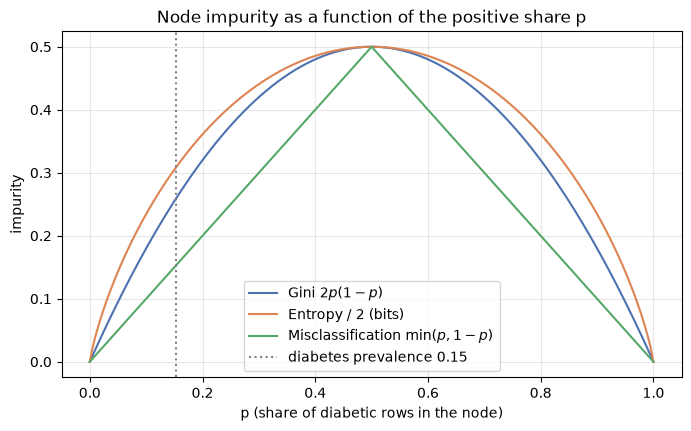

Root node (p = 0.1529): Gini 0.2591, entropy 0.6172 bits


In [5]:
Criterion = Literal["gini", "entropy", "error"]


def impurity(p: FloatArray, criterion: Criterion) -> FloatArray:
    """Impurity of binary nodes whose positive-class share is ``p``.

    Args:
        p: Positive-class share per node, values in [0, 1].
        criterion: ``"gini"``, ``"entropy"`` (bits) or ``"error"`` (misclassification).

    Returns:
        The impurity of every node.
    """
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
    if criterion == "gini":
        return 2.0 * p * (1.0 - p)
    if criterion == "entropy":
        with np.errstate(divide="ignore", invalid="ignore"):
            h = -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))
        return np.nan_to_num(h)  # 0 * log 0 = 0 at pure nodes
    return np.minimum(p, 1.0 - p)


p_grid = np.linspace(0, 1, 201)
plt.plot(p_grid, impurity(p_grid, "gini"), label="Gini $2p(1-p)$", color=BLUE)
plt.plot(p_grid, impurity(p_grid, "entropy") / 2, label="Entropy / 2 (bits)", color=ORANGE)
plt.plot(p_grid, impurity(p_grid, "error"), label="Misclassification $\\min(p,1-p)$", color=GREEN)
plt.axvline(prevalence, color="grey", linestyle=":", label=f"diabetes prevalence {prevalence:.2f}")
plt.title("Node impurity as a function of the positive share p")
plt.xlabel("p (share of diabetic rows in the node)")
plt.ylabel("impurity")
plt.legend()
plt.show()

root_gini = impurity(np.array([prevalence]), "gini")[0]
root_entropy = impurity(np.array([prevalence]), "entropy")[0]
print(f"Root node (p = {prevalence:.4f}): Gini {root_gini:.4f}, entropy {root_entropy:.4f} bits")

## 1.2 CART from scratch

*Split search.* All 21 BRFSS features take few distinct values (BMI has the most, under 100), so for
each feature we count rows per distinct value with `np.bincount`; cumulative sums then give the class
counts left and right of **every** threshold at once. Thresholds are midpoints between consecutive
values present in the node, as in scikit-learn. A split is allowed only if both children keep at least
`min_samples_leaf` rows. Rows can carry weights (AdaBoost needs this); with unit weights the counts are
plain row counts.

*Growth.* A node becomes a leaf when it reaches `max_depth`, has fewer than `2 × min_samples_leaf` rows,
is pure, or has no allowed split; otherwise it is split on the best gain and both children are grown
recursively. *Prediction* routes every row down the tree and returns the leaf's positive share.

In [6]:
class TreeData(NamedTuple):
    """Features pre-encoded for fast split search."""

    x: FloatArray  # raw features, shape (n, d)
    codes: IntArray  # index of each value among its feature's sorted distinct values, shape (n, d)
    values: list[FloatArray]  # sorted distinct values of every feature


def prepare(x: FloatArray) -> TreeData:
    """Encode each feature as integer codes of its sorted distinct values.

    Args:
        x: Feature matrix, shape (n, d).

    Returns:
        The raw matrix with its per-feature codes and distinct values.
    """
    codes = np.empty(x.shape, dtype=np.int64)
    values = []
    for j in range(x.shape[1]):
        uniq, inv = np.unique(x[:, j], return_inverse=True)
        codes[:, j] = inv
        values.append(uniq)
    return TreeData(x, codes, values)


class Split(NamedTuple):
    """A candidate split: rows with ``x[:, feature] <= threshold`` go left."""

    feature: int
    threshold: float
    gain: float


def best_split(td: TreeData, y: IntArray, w: FloatArray, idx: IntArray, criterion: Criterion,
               min_samples_leaf: int) -> Split | None:
    """Find the split of the rows ``idx`` with the largest impurity decrease.

    Args:
        td: Encoded features.
        y: 0/1 labels for all rows.
        w: Row weights for all rows.
        idx: Indices of the rows in this node.
        criterion: Impurity measure.
        min_samples_leaf: Minimum number of rows in each child.

    Returns:
        The best split, or ``None`` if no split leaves both children large enough.
    """
    yi, wi = y[idx], w[idx]
    w_total, w_pos = wi.sum(), (wi * yi).sum()
    parent = impurity(np.array([w_pos / w_total]), criterion)[0]
    best: Split | None = None
    for j in range(td.codes.shape[1]):
        c, m = td.codes[idx, j], len(td.values[j])
        count = np.bincount(c, minlength=m)
        present = count > 0
        if present.sum() < 2:
            continue  # constant feature in this node
        count = count[present]
        w_val = np.bincount(c, weights=wi, minlength=m)[present]
        w_pos_val = np.bincount(c, weights=wi * yi, minlength=m)[present]
        vals = td.values[j][present]
        # Left child = all values up to position k; one candidate per gap between present values.
        n_left = np.cumsum(count)[:-1]
        w_left, pos_left = np.cumsum(w_val)[:-1], np.cumsum(w_pos_val)[:-1]
        w_right, pos_right = w_total - w_left, w_pos - pos_left
        ok = (n_left >= min_samples_leaf) & (len(idx) - n_left >= min_samples_leaf)
        ok &= (w_left > 0) & (w_right > 0)
        if not ok.any():
            continue
        with np.errstate(divide="ignore", invalid="ignore"):
            child = (w_left * impurity(pos_left / w_left, criterion)
                     + w_right * impurity(pos_right / w_right, criterion)) / w_total
        gain = np.where(ok, parent - child, -np.inf)
        k = int(np.argmax(gain))
        if best is None or gain[k] > best.gain:
            best = Split(j, float((vals[k] + vals[k + 1]) / 2), float(gain[k]))
    return best


@dataclass
class Node:
    """A node of a from-scratch CART tree."""

    value: float  # weighted share of positives = predicted P(y = 1) at a leaf
    n_samples: int
    impurity: float
    split: Split | None = None
    left: "Node | None" = None
    right: "Node | None" = None


def grow_tree(td: TreeData, y: IntArray, w: FloatArray | None = None, *, criterion: Criterion = "gini",
              max_depth: int | None = None, min_samples_leaf: int = 1, idx: IntArray | None = None,
              depth: int = 0) -> Node:
    """Grow a CART classification tree recursively.

    Args:
        td: Encoded training features.
        y: 0/1 labels.
        w: Row weights (default: all ones).
        criterion: Impurity measure.
        max_depth: Maximum depth (root = depth 0); ``None`` grows until the other rules stop it.
        min_samples_leaf: Minimum rows per leaf.
        idx: Rows in this node (default: all rows).
        depth: Depth of this node.

    Returns:
        The root of the (sub)tree.
    """
    w = np.ones(len(y)) if w is None else w
    idx = np.arange(len(y)) if idx is None else idx
    p = float((w[idx] * y[idx]).sum() / w[idx].sum())
    node = Node(p, len(idx), float(impurity(np.array([p]), criterion)[0]))
    too_deep = max_depth is not None and depth >= max_depth
    if too_deep or len(idx) < 2 * min_samples_leaf or len(idx) < 2 or node.impurity <= 1e-7:
        return node
    split = best_split(td, y, w, idx, criterion, min_samples_leaf)
    if split is None:
        return node
    go_left = td.x[idx, split.feature] <= split.threshold
    kwargs = {"criterion": criterion, "max_depth": max_depth, "min_samples_leaf": min_samples_leaf}
    node.split = split
    node.left = grow_tree(td, y, w, idx=idx[go_left], depth=depth + 1, **kwargs)
    node.right = grow_tree(td, y, w, idx=idx[~go_left], depth=depth + 1, **kwargs)
    return node


def tree_predict_proba(root: Node, x: FloatArray) -> FloatArray:
    """Route rows down a from-scratch tree and return the leaf probabilities.

    Args:
        root: Fitted tree.
        x: Features, shape (n, d).

    Returns:
        ``P(y = 1)`` for every row.
    """
    out = np.empty(len(x))

    def fill(node: Node, rows: IntArray) -> None:
        if node.split is None:
            out[rows] = node.value
            return
        go_left = x[rows, node.split.feature] <= node.split.threshold
        fill(node.left, rows[go_left])
        fill(node.right, rows[~go_left])

    fill(root, np.arange(len(x)))
    return out


def split_table(root: Node) -> pd.DataFrame:
    """List the internal nodes of a from-scratch tree by their path from the root.

    Args:
        root: Fitted tree.

    Returns:
        One row per split, indexed by path (``""`` = root, ``"L"``, ``"LR"``, ...).
    """
    rows = {}

    def walk(node: Node, path: str) -> None:
        if node.split is not None:
            rows[path] = {"feature": FEATURES[node.split.feature], "threshold": node.split.threshold,
                          "n_samples": node.n_samples}
            walk(node.left, path + "L")
            walk(node.right, path + "R")

    walk(root, "")
    return pd.DataFrame.from_dict(rows, orient="index")


def sklearn_split_table(model: DecisionTreeClassifier) -> pd.DataFrame:
    """The same table for a fitted scikit-learn tree.

    Args:
        model: Fitted ``DecisionTreeClassifier``.

    Returns:
        One row per split, indexed by path from the root.
    """
    t = model.tree_
    rows = {}

    def walk(node: int, path: str) -> None:
        if t.children_left[node] != -1:
            rows[path] = {"feature": FEATURES[t.feature[node]], "threshold": float(t.threshold[node]),
                          "n_samples": int(t.n_node_samples[node])}
            walk(t.children_left[node], path + "L")
            walk(t.children_right[node], path + "R")

    walk(0, "")
    return pd.DataFrame.from_dict(rows, orient="index")


def count_leaves(node: Node) -> int:
    """Number of leaves under ``node``."""
    return 1 if node.split is None else count_leaves(node.left) + count_leaves(node.right)

## 1.3 Check against scikit-learn

Same sample (25,000 training rows), same settings: `max_depth = 6`, `min_samples_leaf = 20`. The two
trees must choose the same splits (feature **and** threshold) and give near-identical probabilities on
the full validation set. scikit-learn breaks exact ties between features in a random order, so a
difference deep in the tree would be acceptable; the first three levels must agree exactly.

In [7]:
CHECK_DEPTH, CHECK_LEAF = 6, 20
td_sample = prepare(xs)
t0 = time.perf_counter()
scratch_tree = grow_tree(td_sample, ys, criterion="gini", max_depth=CHECK_DEPTH, min_samples_leaf=CHECK_LEAF)
t_scratch_tree = time.perf_counter() - t0
sk_tree = DecisionTreeClassifier(criterion="gini", max_depth=CHECK_DEPTH, min_samples_leaf=CHECK_LEAF,
                                 random_state=RANDOM_STATE).fit(xs, ys)

ours_splits, sk_splits = split_table(scratch_tree), sklearn_split_table(sk_tree)
both = ours_splits.add_suffix(" (ours)").join(sk_splits.add_suffix(" (sklearn)"), how="outer")
same = ((both["feature (ours)"] == both["feature (sklearn)"])
        & np.isclose(both["threshold (ours)"], both["threshold (sklearn)"]))
top = both.index.str.len() <= 2  # root + two levels below it = 7 splits
assert same[top].all(), "the first three levels of the two trees differ"

proba_ours = tree_predict_proba(scratch_tree, x_val_np)
proba_sk = sk_tree.predict_proba(x_val_np)[:, 1]
max_diff = float(np.abs(proba_ours - proba_sk).max())
assert max_diff < 1e-9 or np.mean(np.isclose(proba_ours, proba_sk)) > 0.99

print(f"Grown from scratch in {t_scratch_tree:.2f} s; {count_leaves(scratch_tree)} leaves "
      f"(sklearn: {sk_tree.get_n_leaves()})")
print(f"Identical splits: {int(same.sum())} of {len(both)} (first three levels: {int(same[top].sum())} of {int(top.sum())})")
print(f"Validation probabilities: max |ours - sklearn| = {max_diff:.2e}; "
      f"identical for {np.mean(np.isclose(proba_ours, proba_sk)):.2%} of {len(x_val_np):,} rows")
both.head(7)

Grown from scratch in 0.06 s; 64 leaves (sklearn: 64)
Identical splits: 63 of 63 (first three levels: 7 of 7)
Validation probabilities: max |ours - sklearn| = 0.00e+00; identical for 100.00% of 34,421 rows


,feature (ours),threshold (ours),n_samples (ours),feature (sklearn),threshold (sklearn),n_samples (sklearn)
,HighBP,0.5,25000,HighBP,0.5,25000
L,GenHlth,2.5,13645,GenHlth,2.5,13645
LL,Age,6.5,8204,Age,6.5,8204
LLL,HighChol,0.5,3595,HighChol,0.5,3595
LLLL,DiffWalk,0.5,3004,DiffWalk,0.5,3004
LLLLL,MentHlth,0.5,2959,MentHlth,0.5,2959
LLLLR,MentHlth,0.5,45,MentHlth,0.5,45


In [8]:
# Entropy as well. scikit-learn's own entropy tree on this sample depends on random_state (an exact tie
# between two features in one node), so compare with scikit-learn's trees for seeds 0-19.
scratch_entropy = grow_tree(td_sample, ys, criterion="entropy", max_depth=CHECK_DEPTH,
                            min_samples_leaf=CHECK_LEAF)
e_ours = split_table(scratch_entropy)


def same_splits(a: pd.DataFrame, b: pd.DataFrame) -> bool:
    """True if two split tables have the same nodes, features and thresholds."""
    return (a.index.equals(b.index) and bool((a["feature"] == b["feature"]).all())
            and bool(np.allclose(a["threshold"], b["threshold"])))


sk_entropy_trees = [DecisionTreeClassifier(criterion="entropy", max_depth=CHECK_DEPTH, min_samples_leaf=CHECK_LEAF,
                                           random_state=seed).fit(xs, ys) for seed in range(20)]
matching = [seed for seed, t in enumerate(sk_entropy_trees) if same_splits(e_ours, sklearn_split_table(t))]
assert matching, "no scikit-learn entropy tree matches ours"
sk_entropy = sk_entropy_trees[matching[0]]
diff_entropy = np.abs(tree_predict_proba(scratch_entropy, x_val_np) - sk_entropy.predict_proba(x_val_np)[:, 1])
assert diff_entropy.max() < 1e-12
other = sklearn_split_table(sk_entropy_trees[next(s for s in range(20) if s not in matching)])
tie = e_ours.add_suffix(" (ours)").join(other.add_suffix(" (other seed)"), how="outer")
tie = tie[(tie["feature (ours)"] != tie["feature (other seed)"])
          | ~np.isclose(tie["threshold (ours)"], tie["threshold (other seed)"])]
print(f"Entropy tree: identical to scikit-learn's for {len(matching)} of 20 seeds (max |difference| "
      f"{diff_entropy.max():.0e}); the other seeds differ only where two splits tie exactly:")
display(tie)
gini_vs_entropy = np.mean(np.isclose(proba_sk, sk_entropy.predict_proba(x_val_np)[:, 1]))
print(f"Gini and entropy trees give the same probability for {gini_vs_entropy:.1%} of validation rows")

evaluate("CART from scratch (gini, depth 6)", proba_ours, tree_predict_proba(scratch_tree, x_test_np),
         t_scratch_tree, SCRATCH_RESULTS)

Entropy tree: identical to scikit-learn's for 11 of 20 seeds (max |difference| 0e+00); the other seeds differ only where two splits tie exactly:


,feature (ours),threshold (ours),n_samples (ours),feature (other seed),threshold (other seed),n_samples (other seed)
LRLRL,BMI,42.5,51,MentHlth,4.5,51


Gini and entropy trees give the same probability for 47.9% of validation rows


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"CART from scratch (gini, depth 6)",0.0585,0.3886,0.1026,0.89,0.2546,0.3959,0.7976,0.4005,0.1083,15435,13722,579,4686


**Observation: the from-scratch CART is scikit-learn's CART.**
* **Gini:** all 63 splits (feature *and* threshold) are identical, both trees have 64 leaves, and the
  probabilities on all 34,421 validation rows are identical (largest difference 0). Growing the tree
  from scratch takes about 0.06 s on 25,000 rows because the split search is one `bincount` per feature.
* **Entropy:** our tree equals scikit-learn's for 11 of 20 random seeds. The other seeds differ in **one**
  node of 51 rows, where `BMI <= 42.5` and `MentHlth <= 4.5` give exactly the same gain; scikit-learn breaks
  such ties by a random feature order, so its own trees differ between seeds there.
* Gini and entropy are different criteria and pick different splits in places: the two trees give the
  same probability for only 48 % of validation rows.
* On the test set the depth-6 tree trained on 25,000 rows reaches PR-AUC 0.401 (ROC-AUC 0.798) with
  recall 0.89 and precision 0.25 at its F2 threshold.

## 1.4 Reading the tree

The top three levels of the scikit-learn tree above (the from-scratch tree is the same). Each box shows
the question, the Gini impurity, the share of the 25,000 sample rows that reach the node and the class
mix `[no diabetes, diabetes]`; darker orange means a higher diabetic share.

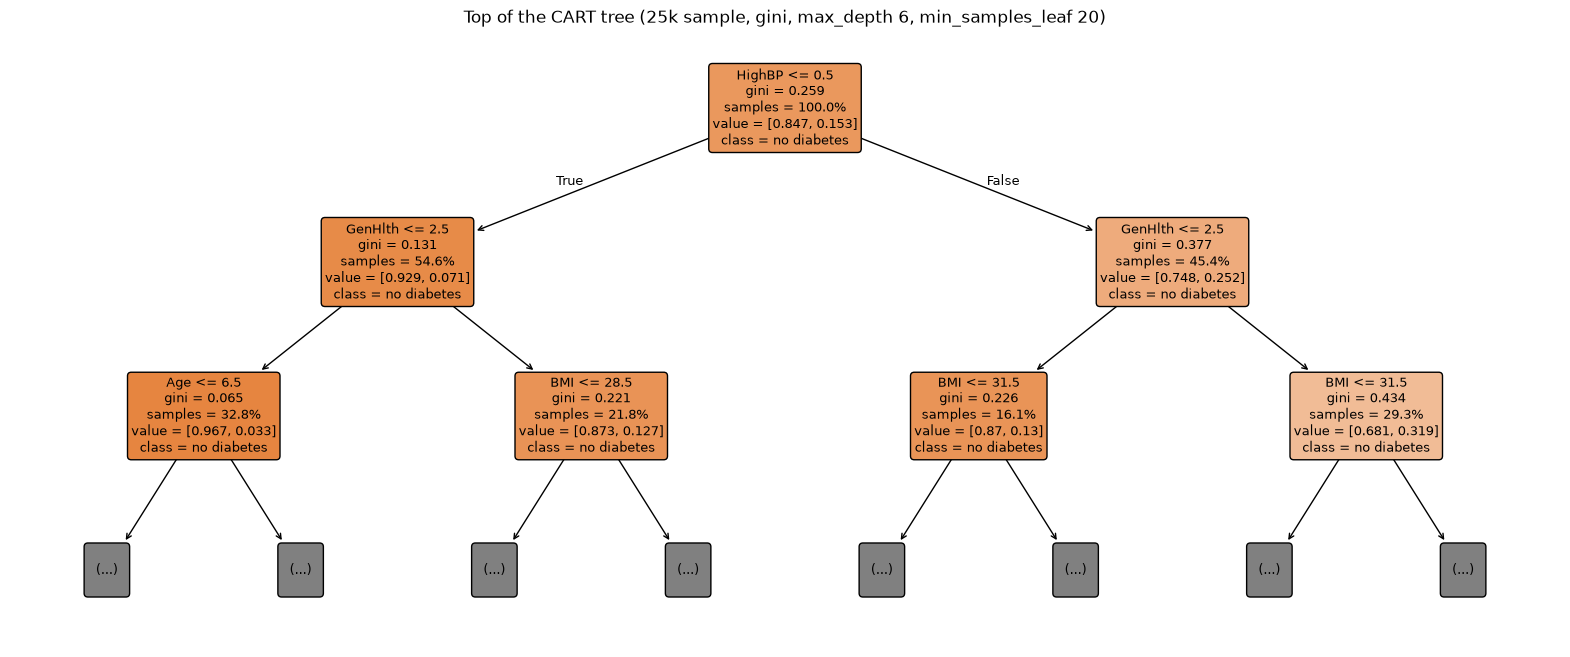

In [9]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(sk_tree, max_depth=2, feature_names=FEATURES, class_names=["no diabetes", "diabetes"],
          filled=True, rounded=True, proportion=True, impurity=True, fontsize=9, ax=ax)
ax.set_title("Top of the CART tree (25k sample, gini, max_depth 6, min_samples_leaf 20)")
plt.show()

**Reading the first splits in plain words** (25,000-row sample; 15.3 % diabetic overall):
1. **High blood pressure** is the first question. People *without* it (55 %) are 7.1 % diabetic; people
   *with* it (45 %) are 25.2 % diabetic.
2. On **both** sides the next question is **self-rated general health**: excellent or very good
   (`GenHlth` 1–2) versus good, fair or poor (3–5). Without high blood pressure and in very good health:
   3.3 % diabetic. With high blood pressure and only good/fair/poor health: 31.9 %.
3. The third level asks **age** (`Age <= 6.5` = under 50) for the healthiest group and **BMI** for the
   others (cut at 28.5 or 31.5, close to the obesity line of 30). The extreme paths: no high blood pressure,
   very good health, under 50, no high cholesterol → **1.3 %** diabetic; high blood pressure, good/fair/poor
   health, BMI ≥ 32, high cholesterol → **41.6 %**.

These are the same risk factors that notebook 01's logistic regression weighted most. The tree shows
**associations in a 2015 survey**, not causes, and each box is a share of survey respondents, not a
person's diagnosis.

## 1.5 Overfitting: depth

A tree can keep splitting until every leaf is pure, which memorises the training rows. Below, trees of
increasing depth are fitted on the **full** training split (scikit-learn, `min_samples_leaf = 1`) and
scored by PR-AUC on training and validation data.

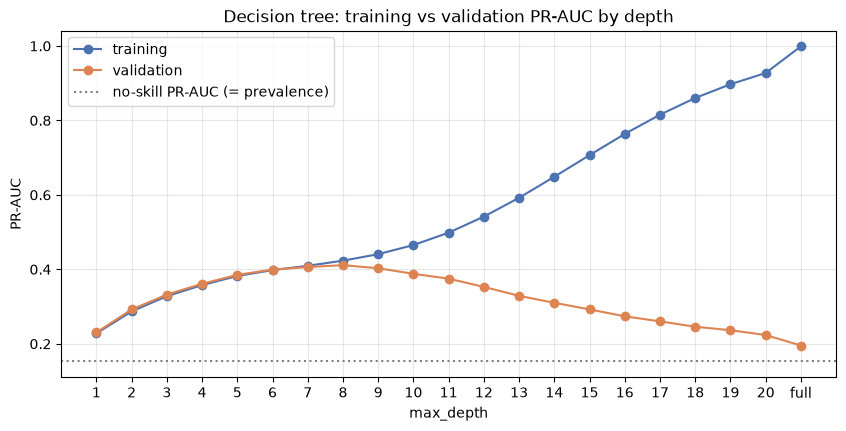

Best validation PR-AUC 0.4112 at depth 8 (253 leaves)


,max_depth,leaves,train PR-AUC,val PR-AUC
0,1,2,0.2280,0.2304
2,3,8,0.3279,0.3322
4,5,32,0.3822,0.3850
6,7,128,0.4095,0.4061
7,8,253,0.4232,0.4112
8,9,493,0.4407,0.4029
10,11,1604,0.4985,0.3749
14,15,7916,0.7067,0.2924
19,20,20253,0.9274,0.2235
20,full,32502,0.9990,0.1952


In [10]:
DEPTHS: list[int | None] = [*range(1, 21), None]
depth_rows = []
for d in DEPTHS:
    tree_d = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(x_train, y_train)
    depth_rows.append({"max_depth": "full" if d is None else d, "leaves": tree_d.get_n_leaves(),
                       "train PR-AUC": average_precision_score(y_train, pos_proba(tree_d, x_train)),
                       "val PR-AUC": average_precision_score(y_val, pos_proba(tree_d, x_val))})
depth_df = pd.DataFrame(depth_rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
xpos = np.arange(len(depth_df))
ax.plot(xpos, depth_df["train PR-AUC"], marker="o", color=BLUE, label="training")
ax.plot(xpos, depth_df["val PR-AUC"], marker="o", color=ORANGE, label="validation")
ax.axhline(prevalence, color="grey", linestyle=":", label="no-skill PR-AUC (= prevalence)")
ax.set_xticks(xpos, depth_df["max_depth"].astype(str))
ax.set(title="Decision tree: training vs validation PR-AUC by depth", xlabel="max_depth", ylabel="PR-AUC")
ax.legend()
plt.show()
best_depth_row = depth_df.loc[depth_df["val PR-AUC"].idxmax()]
print(f"Best validation PR-AUC {best_depth_row['val PR-AUC']:.4f} at depth {best_depth_row['max_depth']} "
      f"({best_depth_row['leaves']:,} leaves)")
depth_df.iloc[[0, 2, 4, 6, 7, 8, 10, 14, 19, 20]]

**Observation: a deep tree memorises the training data.** Training PR-AUC rises steadily with depth
(0.23 at depth 1, 0.71 at depth 15, 0.999 for the full tree with 32,502 leaves), while validation PR-AUC
peaks at **0.411 at depth 8** (253 leaves) and then falls to 0.195 for the full tree — barely above the
no-skill value of 0.153. Up to depth 7 the two curves are on top of each other (the tree is still
*underfitting*); from depth 9 the gap opens quickly. Depth is a blunt control, though: it cuts every
branch at the same level.

## 1.6 Cost-complexity pruning

Instead of stopping early, grow the full tree and then **prune** it. For a subtree $T$ with $|T|$ leaves,
cost-complexity pruning minimises
$$R_\alpha(T) = R(T) + \alpha\,|T|,$$
where $R(T)$ is the total (weighted) leaf impurity on the training data. As $\alpha$ grows, the
*weakest link* — the internal node whose subtree buys the least impurity reduction per extra leaf — is
collapsed first, giving a nested sequence of subtrees (`cost_complexity_pruning_path`). We choose
$\alpha$ by **5-fold stratified cross-validation on the training split** (PR-AUC), then refit on the
whole training split and score the test set as usual.

Pruning path: 10,120 alphas from 0.00e+00 to 1.66e-02


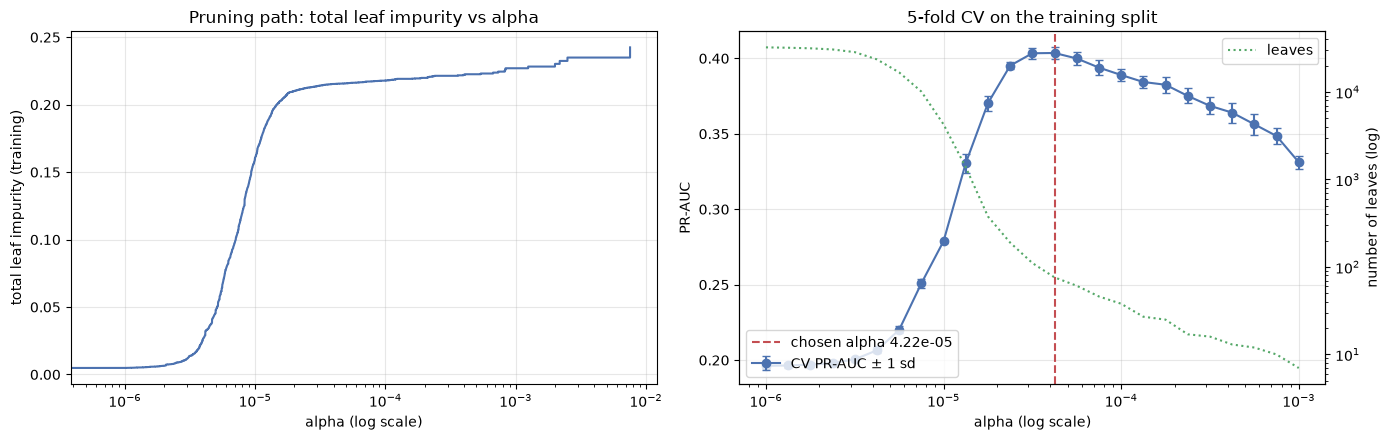

In [11]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(x_train, y_train)
print(f"Pruning path: {len(path.ccp_alphas):,} alphas from {path.ccp_alphas[1]:.2e} to {path.ccp_alphas[-1]:.2e}")

ALPHA_GRID = np.geomspace(1e-6, 1e-3, 25)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {"ccp_alpha": ALPHA_GRID},
                      scoring="average_precision", cv=cv, n_jobs=-1).fit(x_train, y_train)
best_alpha = float(search.best_params_["ccp_alpha"])
cv_mean = search.cv_results_["mean_test_score"]
cv_std = search.cv_results_["std_test_score"]
leaves = [DecisionTreeClassifier(ccp_alpha=a, random_state=RANDOM_STATE).fit(x_train, y_train).get_n_leaves()
          for a in ALPHA_GRID]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].step(path.ccp_alphas[:-1], path.impurities[:-1], where="post", color=BLUE)
axes[0].set(xscale="log", title="Pruning path: total leaf impurity vs alpha",
            xlabel="alpha (log scale)", ylabel="total leaf impurity (training)")
axes[1].errorbar(ALPHA_GRID, cv_mean, yerr=cv_std, marker="o", color=BLUE, capsize=3, label="CV PR-AUC ± 1 sd")
axes[1].axvline(best_alpha, color=RED, linestyle="--", label=f"chosen alpha {best_alpha:.2e}")
axes[1].set(xscale="log", title="5-fold CV on the training split", xlabel="alpha (log scale)", ylabel="PR-AUC")
twin = axes[1].twinx()
twin.plot(ALPHA_GRID, leaves, color=GREEN, linestyle=":", label="leaves")
twin.set(yscale="log", ylabel="number of leaves (log)")
twin.grid(False)
axes[1].legend(loc="lower left")
twin.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [12]:
pruned_tree, t_fit = timed(lambda: DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=RANDOM_STATE)
                           .fit(x_train, y_train))
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(x_train, y_train)
print(f"Chosen alpha {best_alpha:.2e}: {pruned_tree.get_n_leaves()} leaves, depth {pruned_tree.get_depth()} "
      f"(unpruned tree: {full_tree.get_n_leaves():,} leaves, depth {full_tree.get_depth()})")
print(f"CV PR-AUC at the chosen alpha: {cv_mean[np.argmax(cv_mean)]:.4f} ± {cv_std[np.argmax(cv_mean)]:.4f}")
display(evaluate("Unpruned tree (for reference)", pos_proba(full_tree, x_val), pos_proba(full_tree, x_test),
                 0.0, SCRATCH_RESULTS).drop(columns="fit time (s)"))
SCRATCH_RESULTS.pop("Unpruned tree (for reference)")  # shown once here; not a from-scratch model
evaluate("CART (pruned)", pos_proba(pruned_tree, x_val), pos_proba(pruned_tree, x_test), t_fit)

Chosen alpha 4.22e-05: 76 leaves, depth 10 (unpruned tree: 32,502 leaves, depth 42)
CV PR-AUC at the chosen alpha: 0.4036 ± 0.0037


,val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
Unpruned tree (for reference),0.1952,0.0,1.0,0.153,0.2653,0.5861,0.1949,0.2289,0,29157,0,5265


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
CART (pruned),1.2503,0.4085,0.1265,0.8444,0.2763,0.4164,0.8027,0.4203,0.107,17513,11644,819,4446


**Observation: pruning gives a small tree as good as the best depth-limited one.**
* The pruning path has 10,120 values of α. Cross-validated PR-AUC is low for tiny α (almost the full,
  memorising tree), peaks at **α = 4.2 × 10⁻⁵** (CV PR-AUC 0.404 ± 0.004) and falls again when α prunes
  away real structure. The curve is flat near the top, so any α between about 3 × 10⁻⁵ and 6 × 10⁻⁵ would
  do.
* The pruned tree has **76 leaves** (depth 10) instead of 32,502 (depth 42). It keeps deep branches only
  where they pay off, which is why it is deeper than the best depth-limited tree but has 3× fewer leaves
  (76 vs 253) at similar validation PR-AUC (0.409 vs 0.411).
* **Test:** PR-AUC 0.420, ROC-AUC 0.803, recall 0.844, precision 0.276, F1 0.416, Brier 0.107 — the same
  PR-AUC as notebook 01's logistic regression (0.420; the difference is +0.000 with a 95 % interval of
  −0.007 to +0.008, Section 4).
* The **unpruned** tree's leaves hold one or a few people, so almost all its probabilities are exactly
  0 or 1. Its F2-optimal threshold on validation is therefore 0: it flags everybody (recall 1.0,
  precision 0.153). That is what overfitting looks like in a screening setting.

## 1.7 Feature importance: impurity-based vs permutation

* **Impurity-based** (`feature_importances_`): the total weighted Gini decrease of every split on a feature,
  normalised to sum to 1. It is free to compute but is measured on the **training** data.
* **Permutation**: shuffle one feature in the **validation** set and measure how much PR-AUC drops
  (5 repeats). It measures what the model needs to predict new people.

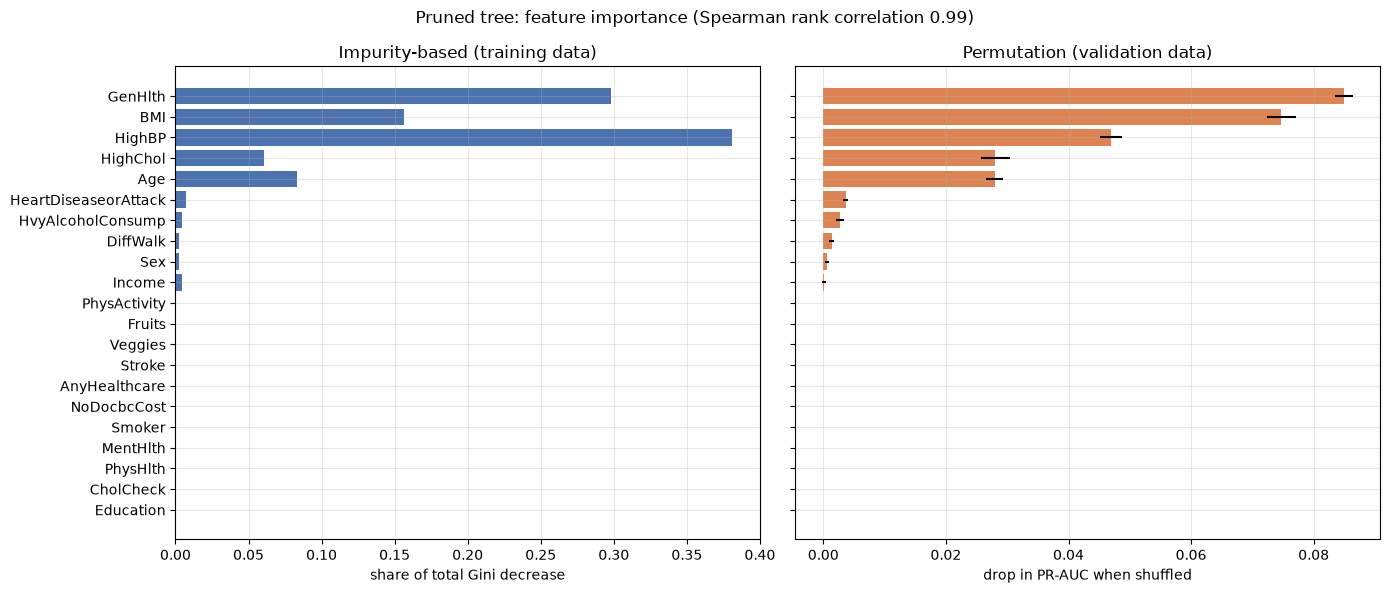

,impurity (share),permutation (PR-AUC drop),permutation sd,rank impurity,rank permutation
GenHlth,0.2979,8.4940e-02,0.0015,2,1
BMI,0.1561,7.4693e-02,0.0024,3,2
HighBP,0.3811,4.6900e-02,0.0018,1,3
HighChol,0.0604,2.8060e-02,0.0024,5,4
Age,0.0832,2.7945e-02,0.0013,4,5
HeartDiseaseorAttack,0.0074,3.6707e-03,0.0004,6,6
HvyAlcoholConsump,0.0047,2.6947e-03,0.0007,7,7
DiffWalk,0.0025,1.3782e-03,0.0004,9,8
Sex,0.0023,6.0729e-04,0.0004,10,9
Income,0.0043,7.8308e-05,0.0003,8,10


In [13]:
perm = permutation_importance(pruned_tree, x_val, y_val, scoring="average_precision", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({
    "impurity (share)": pruned_tree.feature_importances_,
    "permutation (PR-AUC drop)": perm.importances_mean,
    "permutation sd": perm.importances_std,
}, index=FEATURES)
importance["rank impurity"] = importance["impurity (share)"].rank(ascending=False).astype(int)
importance["rank permutation"] = importance["permutation (PR-AUC drop)"].rank(ascending=False).astype(int)
importance = importance.sort_values("permutation (PR-AUC drop)", ascending=False)
rho = spearmanr(importance["impurity (share)"], importance["permutation (PR-AUC drop)"]).statistic

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = importance.index[::-1]
axes[0].barh(order, importance.loc[order, "impurity (share)"], color=BLUE)
axes[0].set(title="Impurity-based (training data)", xlabel="share of total Gini decrease")
axes[1].barh(order, importance.loc[order, "permutation (PR-AUC drop)"],
             xerr=importance.loc[order, "permutation sd"], color=ORANGE)
axes[1].set(title="Permutation (validation data)", xlabel="drop in PR-AUC when shuffled")
plt.suptitle(f"Pruned tree: feature importance (Spearman rank correlation {rho:.2f})")
plt.tight_layout()
plt.show()
importance.head(10)

**Observation: the two importances agree on the top five features but not on their order.**
* **Impurity-based** puts **HighBP** first (38 % of the total Gini decrease), then GenHlth (30 %) and BMI
  (16 %). **Permutation** puts **GenHlth** first (PR-AUC drops by 0.085 when it is shuffled), then BMI
  (0.075) and only then HighBP (0.047).
* Why they differ:
  1. *HighBP is the root split.* The root is evaluated on all rows, so its Gini decrease is large. But
     GenHlth, BMI and Age are used again in **both** branches below it, so when HighBP is shuffled the lower
     splits recover much of what it carried. Permutation measures what is lost; impurity measures where the
     tree happened to use a feature first.
  2. *Different data and different yardstick:* impurity is computed on the training rows with the Gini
     criterion; permutation on held-out validation rows with PR-AUC.
  3. *Correlated features* (HighBP, HighChol, Age, BMI, GenHlth all move together) share credit in
     unpredictable ways under both methods, and shuffling one of them creates unrealistic combinations.
  4. Impurity importance is known to favour features with many distinct values (BMI); pruning removed most
     of the noisy BMI splits, so the bias is small here.
* The Spearman correlation of 0.99 is inflated: 11 of the 21 features are never used by the pruned tree
  and score zero under both methods. Both methods agree that the top five (GenHlth, BMI, HighBP, HighChol,
  Age) carry almost all of the signal.

# 2. Ensemble learning

A single tree has **high variance**: a slightly different training set can give a very different tree.
Ensembles combine many models so that their individual errors partly cancel.

## 2.1 Bagging from scratch

**Bootstrap aggregating:** draw $B$ bootstrap samples (size $n$, with replacement) from the training data,
fit one deep tree to each, and **average their predicted probabilities**. A bootstrap sample is a
multiset, so it is stored as a count per row (how many times the row was drawn, 0 for the about 37 % of
rows left out); fitting a tree with those counts as sample weights is the same as fitting it on the
repeated rows. The base learner is scikit-learn's `DecisionTreeClassifier` (unpruned), which Section 1.3
showed equals our CART; the bagging procedure itself is written here.

Runs on the 25,000-row sample.

In [14]:
class BaggedTrees(NamedTuple):
    """A bagged ensemble of trees."""

    trees: list[DecisionTreeClassifier]
    counts: list[IntArray]  # times each training row was drawn, one array per tree


def bagging_fit(x: FloatArray, y: IntArray, n_trees: int, seed: int = RANDOM_STATE,
                bootstrap_indices: list[IntArray] | None = None, tree_seeds: list[int] | None = None,
                **tree_params: object) -> BaggedTrees:
    """Fit one tree per bootstrap sample.

    Args:
        x: Training features.
        y: 0/1 labels.
        n_trees: Number of bootstrap samples / trees.
        seed: Seed for drawing the bootstrap samples.
        bootstrap_indices: Optional pre-drawn bootstrap indices (used to reproduce scikit-learn exactly).
        tree_seeds: Optional ``random_state`` per tree (only breaks ties between equally good splits).
        **tree_params: Passed to ``DecisionTreeClassifier``.

    Returns:
        The fitted trees and their bootstrap counts.
    """
    rng = np.random.default_rng(seed)
    trees, counts = [], []
    for b in range(n_trees):
        idx = bootstrap_indices[b] if bootstrap_indices is not None else rng.integers(0, len(x), len(x))
        count = np.bincount(idx, minlength=len(x))
        tree = DecisionTreeClassifier(random_state=tree_seeds[b] if tree_seeds else b, **tree_params)
        trees.append(tree.fit(x, y, sample_weight=count))
        counts.append(count)
    return BaggedTrees(trees, counts)


def bagging_proba(model: BaggedTrees, x: FloatArray, staged: bool = False) -> FloatArray:
    """Average the trees' probabilities.

    Args:
        model: Fitted bagged trees.
        x: Features.
        staged: If true, return the average of the first 1, 2, ..., B trees (shape (B, n)).

    Returns:
        ``P(y = 1)`` per row, or per number of trees and row.
    """
    per_tree = np.vstack([t.predict_proba(x)[:, 1] for t in model.trees])
    if staged:
        return np.cumsum(per_tree, axis=0) / np.arange(1, len(per_tree) + 1)[:, None]
    return per_tree.mean(axis=0)


N_BAG = 100
bag_ours, t_bag = timed(lambda: bagging_fit(xs, ys, N_BAG))
sk_bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=N_BAG, random_state=RANDOM_STATE,
                           n_jobs=-1).fit(xs, ys)

# (1) Exact check: our procedure with scikit-learn's bootstrap draws must reproduce it exactly.
bag_same = bagging_fit(xs, ys, N_BAG, bootstrap_indices=list(sk_bag.estimators_samples_),
                       tree_seeds=[e.random_state for e in sk_bag.estimators_])
exact_diff = np.abs(bagging_proba(bag_same, x_val_np) - sk_bag.predict_proba(x_val_np)[:, 1]).max()
assert exact_diff < 1e-12, exact_diff

# (2) Independent check: our own bootstrap draws give the same quality.
val_ours = bagging_proba(bag_ours, x_val_np)
ap_ours = average_precision_score(y_val, val_ours)
ap_sk = average_precision_score(y_val, sk_bag.predict_proba(x_val_np)[:, 1])
assert abs(ap_ours - ap_sk) < 0.01
print(f"Same bootstrap draws: max |ours - BaggingClassifier| = {exact_diff:.1e}")
print(f"Own bootstrap draws: validation PR-AUC ours {ap_ours:.4f}  vs  BaggingClassifier {ap_sk:.4f}")
oob_share = np.mean([np.mean(c == 0) for c in bag_ours.counts])
print(f"Average share of rows left out of a bootstrap sample: {oob_share:.3f} (theory: 1/e = {np.exp(-1):.3f})")

evaluate(f"Bagging from scratch ({N_BAG} trees)", val_ours, bagging_proba(bag_ours, x_test_np), t_bag,
         SCRATCH_RESULTS)

Same bootstrap draws: max |ours - BaggingClassifier| = 1.1e-16
Own bootstrap draws: validation PR-AUC ours 0.3473  vs  BaggingClassifier 0.3504
Average share of rows left out of a bootstrap sample: 0.368 (theory: 1/e = 0.368)


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
Bagging from scratch (100 trees),3.0622,0.3473,0.102,0.8551,0.2464,0.3825,0.7733,0.3636,0.1155,15386,13771,763,4502


### Variance reduction

To see the variance directly, we simulate **15 different training sets** (each a bootstrap of the
25,000-row sample) and on each fit (a) one deep tree and (b) a bag of 25 deep trees. For 2,000 fixed
validation people we then measure how much each prediction moves between training sets (its standard
deviation across the 15 fits). Then: validation PR-AUC as trees are added to the 100-tree bag.

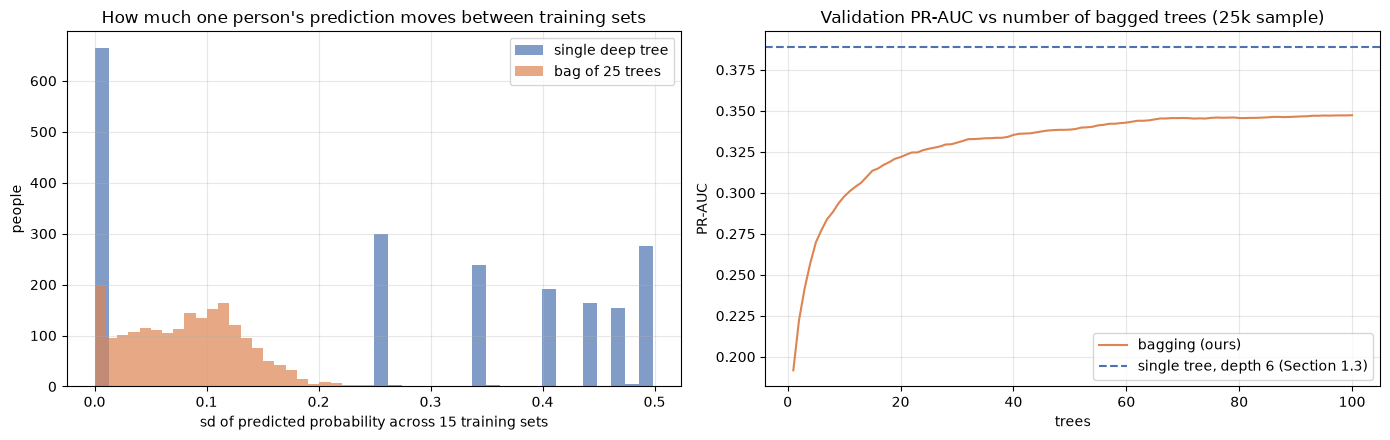

,single deep tree,bag of 25 trees
mean sd of a person's probability across training sets,0.2592,0.0818
sd of PR-AUC across training sets,0.0109,0.0111
mean PR-AUC,0.1988,0.3406


In [15]:
N_REPEATS, N_SMALL_BAG = 15, 25
probe_idx, _ = train_test_split(np.arange(len(x_val_np)), train_size=2000, stratify=y_val,
                                random_state=RANDOM_STATE)
x_probe, y_probe = x_val_np[probe_idx], y_val[probe_idx]
single_preds = np.empty((N_REPEATS, len(x_probe)))
bag_preds = np.empty((N_REPEATS, len(x_probe)))
for r in range(N_REPEATS):
    draw = np.random.default_rng(RANDOM_STATE + r).integers(0, len(xs), len(xs))
    single = DecisionTreeClassifier(random_state=r).fit(xs[draw], ys[draw])
    single_preds[r] = single.predict_proba(x_probe)[:, 1]
    bag_preds[r] = bagging_proba(bagging_fit(xs[draw], ys[draw], N_SMALL_BAG, seed=1000 + r), x_probe)

spread = pd.DataFrame({
    "single deep tree": [single_preds.std(axis=0).mean(),
                         np.std([average_precision_score(y_probe, p) for p in single_preds]),
                         np.mean([average_precision_score(y_probe, p) for p in single_preds])],
    f"bag of {N_SMALL_BAG} trees": [bag_preds.std(axis=0).mean(),
                                    np.std([average_precision_score(y_probe, p) for p in bag_preds]),
                                    np.mean([average_precision_score(y_probe, p) for p in bag_preds])],
}, index=["mean sd of a person's probability across training sets", "sd of PR-AUC across training sets",
          "mean PR-AUC"])

staged = bagging_proba(bag_ours, x_val_np, staged=True)
staged_ap = [average_precision_score(y_val, p) for p in staged]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(single_preds.std(axis=0), bins=40, alpha=0.7, color=BLUE, label="single deep tree")
axes[0].hist(bag_preds.std(axis=0), bins=40, alpha=0.7, color=ORANGE, label=f"bag of {N_SMALL_BAG} trees")
axes[0].set(title="How much one person's prediction moves between training sets",
            xlabel="sd of predicted probability across 15 training sets", ylabel="people")
axes[0].legend()
axes[1].plot(np.arange(1, N_BAG + 1), staged_ap, color=ORANGE, label="bagging (ours)")
axes[1].axhline(average_precision_score(y_val, tree_predict_proba(scratch_tree, x_val_np)), color=BLUE,
                linestyle="--", label="single tree, depth 6 (Section 1.3)")
axes[1].set(title="Validation PR-AUC vs number of bagged trees (25k sample)", xlabel="trees",
            ylabel="PR-AUC")
axes[1].legend()
plt.tight_layout()
plt.show()
spread

**Observation: bagging removes most of a deep tree's variance, not its bias.**
* **Check:** fed scikit-learn's own bootstrap draws, our bagging reproduces `BaggingClassifier` to
  1 × 10⁻¹⁶. With independent draws the validation PR-AUC is 0.347 (ours) vs 0.350 (scikit-learn). On
  average 36.8 % of rows are left out of a bootstrap sample, as the theory says (1/e).
* **Variance:** across 15 training sets, one person's predicted probability from a single deep tree moves
  by 0.26 on average (standard deviation): for many people the deep tree's prediction flips between 0
  and 1 from one training set to the next (the spikes at 0.26–0.5 in the histogram). A bag of 25 trees moves by 0.08 — about a tenth of the variance — and its mean PR-AUC is
  0.34 instead of 0.20.
* **Number of trees:** validation PR-AUC climbs quickly over the first 20 trees and has flattened by
  60–100 trees. More trees never hurt; they just stop helping.
* **But** the bag of fully grown trees (0.35) stays **below a single depth-6 tree** (0.39). Each deep tree's
  leaves hold one or two people, so the bag can only average coarse 0/1 votes: bagging cures variance,
  not this. With leaves of at least 20 people on the full data (next section) bagging reaches test
  PR-AUC 0.437, above the pruned tree (0.420).

## 2.2 Random forest on the full data: what feature subsampling adds

A random forest is bagging plus one change: at **every split** a tree may only look at a random subset of
`max_features` features (scikit-learn's default for classification: $\sqrt{21} \approx 4$). If $B$ trees
each have variance $\sigma^2$ and pairwise correlation $\rho$, their average has variance
$$\rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$
More trees only shrink the second term; bagged trees grown on the same strong features (BMI, GenHlth,
HighBP, Age) are highly correlated, so the first term dominates. Feature subsampling **lowers $\rho$**.

Both ensembles below use 200 trees with `min_samples_leaf = 20` (the app's random-forest setting), on the
full training split. To measure $\rho$ and $\sigma^2$ directly, the `max_features` sweep below refits each
forest on 5 fresh bootstrap copies of the training split and looks at how 2,000 validation people's
predictions move. The **out-of-bag (OOB)** estimate scores every training row using only the trees whose
bootstrap sample did not contain it — a free validation estimate.

In [16]:
N_FOREST = 200
bagging_full, t_bag_full = timed(lambda: BaggingClassifier(
    DecisionTreeClassifier(min_samples_leaf=20), n_estimators=N_FOREST, oob_score=True, n_jobs=-1,
    random_state=RANDOM_STATE).fit(x_train_np, y_train))
forest, t_forest = timed(lambda: RandomForestClassifier(
    n_estimators=N_FOREST, min_samples_leaf=20, max_features="sqrt", oob_score=True, n_jobs=-1,
    random_state=RANDOM_STATE).fit(x_train_np, y_train))


rows = {}
for name, model in [("Bagging (all 21 features per split)", bagging_full),
                    ("Random forest (sqrt -> 4 features per split)", forest)]:
    rows[name] = {"OOB PR-AUC": average_precision_score(y_train, model.oob_decision_function_[:, 1]),
                  "val PR-AUC": average_precision_score(y_val, pos_proba(model, x_val_np)),
                  "OOB ROC-AUC": roc_auc_score(y_train, model.oob_decision_function_[:, 1]),
                  "val ROC-AUC": roc_auc_score(y_val, pos_proba(model, x_val_np))}
pd.DataFrame(rows).T

,OOB PR-AUC,val PR-AUC,OOB ROC-AUC,val ROC-AUC
Bagging (all 21 features per split),0.4213,0.4231,0.8050,0.8083
Random forest (sqrt -> 4 features per split),0.4281,0.4328,0.8109,0.8156


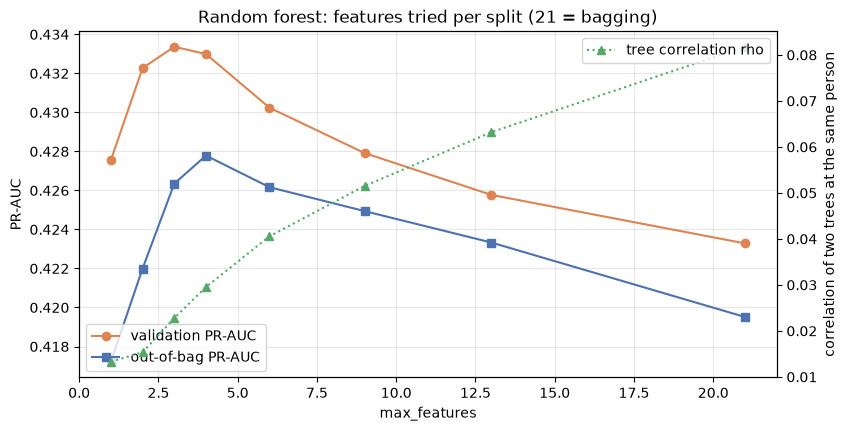

,OOB PR-AUC,val PR-AUC,single-tree variance,tree correlation rho,forest variance (rho*sigma^2)
max_features,,,,,
1,0.4172,0.4276,0.0091,0.0133,0.00012
2,0.4220,0.4323,0.0096,0.0154,0.00015
3,0.4263,0.4334,0.0109,0.0228,0.00025
4,0.4278,0.4330,0.0121,0.0295,0.00036
6,0.4262,0.4302,0.0137,0.0406,0.00056
9,0.4249,0.4279,0.0154,0.0515,0.00079
13,0.4233,0.4258,0.0168,0.0632,0.00106
21,0.4195,0.4233,0.0184,0.0818,0.00150


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"Bagging (200 trees, leaf 20)",9.9008,0.4231,0.1066,0.8678,0.273,0.4153,0.8129,0.4371,0.1058,16990,12167,696,4569


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"Random forest (200 trees, leaf 20)",3.6426,0.4328,0.1281,0.8536,0.2872,0.4298,0.8186,0.4477,0.1051,18002,11155,771,4494


In [17]:
def variance_decomposition(max_features: int, n_sets: int = 5, n_trees: int = 40) -> dict[str, float]:
    """Estimate single-tree variance, tree correlation and forest variance across training sets.

    Fits ``n_sets`` forests, each on a fresh bootstrap of the full training split, and predicts the 2,000
    probe people. sigma^2 = variance of one tree's prediction over training sets and tree randomness;
    the variance of an infinitely large forest over training sets is rho * sigma^2.

    Args:
        max_features: Features tried per split.
        n_sets: Number of simulated training sets.
        n_trees: Trees per forest.

    Returns:
        Average sigma^2, rho and forest variance over the probe people.
    """
    preds = np.empty((n_sets, n_trees, len(x_probe)))
    for r in range(n_sets):
        draw = np.random.default_rng(RANDOM_STATE + r).integers(0, len(x_train_np), len(x_train_np))
        rf_r = RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=20, max_features=max_features,
                                      n_jobs=-1, random_state=r).fit(x_train_np[draw], y_train[draw])
        preds[r] = np.vstack([t.predict_proba(x_probe)[:, 1] for t in rf_r.estimators_])
    sigma2 = preds.reshape(n_sets * n_trees, -1).var(axis=0, ddof=1)
    within = preds.var(axis=1, ddof=1).mean(axis=0)  # tree-to-tree variance inside one forest
    # Variance of the forest mean over training sets, minus the part due to having only n_trees trees.
    forest_var = np.clip(preds.mean(axis=1).var(axis=0, ddof=1) - within / n_trees, 0, None)
    return {"single-tree variance": sigma2.mean(), "tree correlation rho": forest_var.mean() / sigma2.mean(),
            "forest variance (rho*sigma^2)": forest_var.mean()}


# How much subsampling? Sweep max_features (100 trees each for the scores, same other settings).
mf_rows = []
for mf in [1, 2, 3, 4, 6, 9, 13, 21]:
    rf_mf = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_features=mf, oob_score=True,
                                   n_jobs=-1, random_state=RANDOM_STATE).fit(x_train_np, y_train)
    mf_rows.append({"max_features": mf,
                    "OOB PR-AUC": average_precision_score(y_train, rf_mf.oob_decision_function_[:, 1]),
                    "val PR-AUC": average_precision_score(y_val, pos_proba(rf_mf, x_val_np)),
                    **variance_decomposition(mf)})
mf_df = pd.DataFrame(mf_rows).set_index("max_features")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mf_df.index, mf_df["val PR-AUC"], marker="o", color=ORANGE, label="validation PR-AUC")
ax.plot(mf_df.index, mf_df["OOB PR-AUC"], marker="s", color=BLUE, label="out-of-bag PR-AUC")
ax.set(title="Random forest: features tried per split (21 = bagging)", xlabel="max_features", ylabel="PR-AUC")
twin = ax.twinx()
twin.plot(mf_df.index, mf_df["tree correlation rho"], color=GREEN, linestyle=":", marker="^",
          label="tree correlation rho")
twin.set_ylabel("correlation of two trees at the same person")
twin.grid(False)
ax.legend(loc="lower left")
twin.legend(loc="upper right")
plt.show()
display(mf_df.style.format({"single-tree variance": "{:.4f}", "forest variance (rho*sigma^2)": "{:.5f}"},
                           precision=4))

display(evaluate(f"Bagging ({N_FOREST} trees, leaf 20)", pos_proba(bagging_full, x_val_np),
                 pos_proba(bagging_full, x_test_np), t_bag_full))
evaluate(f"Random forest ({N_FOREST} trees, leaf 20)", pos_proba(forest, x_val_np), pos_proba(forest, x_test_np),
         t_forest)

**Observation: feature subsampling lowers the trees' correlation, as the theory says, but the best
setting balances that against weaker trees.**
* **Out-of-bag vs validation:** OOB PR-AUC is 0.421 (bagging) and 0.428 (forest) against 0.423 and 0.433
  on validation, i.e. within 0.005 and slightly pessimistic (each OOB prediction uses only the ~37 % of
  trees that did not see that row). OOB is a reliable free estimate here.
* **Correlation:** ρ — the correlation of two trees' predictions for the same person across training
  sets — rises from 0.013 with 1 feature per split to **0.082 with all 21 (bagging)**, and the variance of
  the whole forest across training sets (ρσ²) rises 12-fold, from 0.00012 to 0.00150. That is exactly the
  ρσ² term in the formula above.
* **But** fewer features also make each tree worse (bias): with 1 feature per split the validation PR-AUC
  is 0.428. The best is **3–4 features** (0.433), which is scikit-learn's default √21 ≈ 4.
* **Overall gain is modest:** test PR-AUC 0.448 (random forest) vs 0.437 (bagging), and the forest is
  about 3× faster to train because each split looks at fewer features. Even the bagging ensemble's
  variance is small in absolute terms (`min_samples_leaf = 20` on 160,000 rows already makes trees stable),
  so most of the remaining error is **bias** — which is what boosting attacks next.

## 2.3 Combining different models: soft voting and stacking

Bagging and random forests average many copies of **one** kind of model. Voting and stacking combine
**different** kinds, hoping their mistakes differ:

* **Soft voting:** average the predicted probabilities of logistic regression (notebook 01), the random
  forest above and gradient boosting (XGBoost with notebook 01's settings, not class-weighted).
* **Stacking:** a logistic-regression **meta-model** learns how much to trust each base model. To avoid
  leakage it is trained on **out-of-fold** predictions: each base model's prediction for a training row
  comes from a copy fitted on the other 4 folds (5-fold stratified CV). The base models are then refitted
  on all training rows for prediction.

In [18]:
def make_forest() -> RandomForestClassifier:
    """The random forest of Section 2.2 (unfitted)."""
    return RandomForestClassifier(n_estimators=N_FOREST, min_samples_leaf=20, max_features="sqrt",
                                  n_jobs=-1, random_state=RANDOM_STATE)


def make_xgb(**overrides: object) -> XGBClassifier:
    """XGBoost with notebook 01's settings (no class weighting unless overridden)."""
    params = {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 5, "subsample": 0.8,
              "colsample_bytree": 0.8, "eval_metric": "logloss", "n_jobs": -1, "random_state": RANDOM_STATE}
    return XGBClassifier(**{**params, **overrides})


base_models = [("logistic", make_logistic()), ("forest", make_forest()), ("xgboost", make_xgb())]
voting, t_vote = timed(lambda: VotingClassifier(base_models, voting="soft").fit(x_train, y_train))
stacking, t_stack = timed(lambda: StackingClassifier(
    base_models, final_estimator=LogisticRegression(max_iter=1000), stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)).fit(x_train, y_train))

base_val = pd.DataFrame({name: pos_proba(m, x_val) for name, m in voting.named_estimators_.items()})
summary = pd.DataFrame({
    "val PR-AUC": {**{n: average_precision_score(y_val, p) for n, p in base_val.items()},
                   "soft voting": average_precision_score(y_val, pos_proba(voting, x_val)),
                   "stacking": average_precision_score(y_val, pos_proba(stacking, x_val))},
    "val ROC-AUC": {**{n: roc_auc_score(y_val, p) for n, p in base_val.items()},
                    "soft voting": roc_auc_score(y_val, pos_proba(voting, x_val)),
                    "stacking": roc_auc_score(y_val, pos_proba(stacking, x_val))},
})
print("Correlation of the base models' validation probabilities:")
display(base_val.corr().round(3))
meta = stacking.final_estimator_
print("Stacking meta-model: logit P(diabetes) = "
      f"{meta.intercept_[0]:+.2f} " + " ".join(f"{c:+.2f}*p_{n}" for n, c in zip(base_val.columns, meta.coef_[0])))
display(summary)

display(evaluate("Soft voting (LR + RF + XGB)", pos_proba(voting, x_val), pos_proba(voting, x_test), t_vote))
evaluate("Stacking (LR meta-model)", pos_proba(stacking, x_val), pos_proba(stacking, x_test), t_stack)

Correlation of the base models' validation probabilities:


,logistic,forest,xgboost
logistic,1.000,0.935,0.932
forest,0.935,1.000,0.977
xgboost,0.932,0.977,1.000


Stacking meta-model: logit P(diabetes) = -3.14 -0.11*p_logistic +3.62*p_forest +3.54*p_xgboost


,val PR-AUC,val ROC-AUC
logistic,0.4089,0.8095
forest,0.4328,0.8156
xgboost,0.4383,0.8178
soft voting,0.4352,0.8175
stacking,0.4382,0.8182


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
Soft voting (LR + RF + XGB),3.3034,0.4352,0.1093,0.8788,0.2784,0.4228,0.821,0.4504,0.1045,17162,11995,638,4627


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
Stacking (LR meta-model),17.2328,0.4382,0.1003,0.8386,0.3009,0.4429,0.822,0.4532,0.1053,18898,10259,850,4415


**Observation: combining models does not beat the best single model here.**
* The three base models agree strongly: their validation probabilities correlate 0.93–0.98, so there is
  little independent error left to average away.
* **Soft voting** (validation PR-AUC 0.435) lands between its members: better than logistic regression
  (0.409) and the forest (0.433), worse than XGBoost alone (0.438). Equal weights let the weakest member
  pull the average down.
* **Stacking** (0.438) learns that: its meta-model gives logistic regression a weight of −0.11 and the
  forest and XGBoost +3.6 and +3.5, so it is essentially "average the forest and XGBoost". It matches
  XGBoost on validation and on test (0.453 vs the tuned XGBoost's 0.455 in Section 4) while taking about
  7× longer to train (16.6 s, because every base model is fitted six times).
* Conclusion for this data: the extra machinery is not worth it. When the base models are this
  correlated, a single well-tuned boosted model is as good.

# 3. Boosting

Bagging fits models **independently** and averages them to cut variance. Boosting fits models
**sequentially**, each one concentrating on what the ensemble so far gets wrong, which mainly cuts
**bias**: it turns many weak learners (here: stumps or small trees) into a strong one.

## 3.1 AdaBoost from scratch (decision stumps)

Labels $y_i \in \{-1, +1\}$, weights $w_i = 1/n$. For rounds $m = 1, \dots, M$:

1. Fit a **stump** $h_m$ (a depth-1 tree predicting $\pm 1$) that minimises the **weighted error**
   $\;\varepsilon_m = \sum_i w_i\,[h_m(x_i) \ne y_i] \,/\, \sum_i w_i$.
2. Its vote: $\;\alpha_m = \tfrac12 \ln\dfrac{1-\varepsilon_m}{\varepsilon_m}$ (large when the error is small; 0 at
   $\varepsilon = 0.5$, i.e. chance).
3. Re-weight: $\;w_i \leftarrow w_i\, e^{-\alpha_m y_i h_m(x_i)}$ — misclassified rows are multiplied by
   $\sqrt{(1-\varepsilon_m)/\varepsilon_m} > 1$, correct ones divided by it — then **normalise** so $\sum_i w_i = 1$.

The ensemble is $F_M(x) = \sum_m \alpha_m h_m(x)$ with prediction $\operatorname{sign} F_M(x)$. AdaBoost minimises
the exponential loss $e^{-yF}$, whose minimiser is $F = \tfrac12 \log\frac{p}{1-p}$ (Friedman, Hastie and
Tibshirani, 2000), so $p = 1 / (1 + e^{-2F})$ turns the score into a probability for PR-AUC and Brier.

The stump search reuses `best_split` from Section 1.2 with weights and `criterion="error"`, which minimises
the weighted misclassification error directly. Runs on the 25,000-row sample, 300 rounds.

In [19]:
class Stump(NamedTuple):
    """A decision stump: predict ``left`` if ``x[:, feature] <= threshold`` else ``right`` (each +1 or -1)."""

    feature: int
    threshold: float
    left: int
    right: int


class AdaBoostModel(NamedTuple):
    """A fitted from-scratch AdaBoost ensemble and its training history."""

    stumps: list[Stump]
    alphas: FloatArray  # vote of each stump
    errors: FloatArray  # weighted training error of each stump
    top_weight_share: FloatArray  # share of total weight held by the top 1 %, 5 %, 10 % of rows, per round
    final_weights: FloatArray  # sample weights after the last round


def stump_predict(stump: Stump, x: FloatArray) -> IntArray:
    """Predict +1/-1 with one stump."""
    return np.where(x[:, stump.feature] <= stump.threshold, stump.left, stump.right)


def fit_stump(td: TreeData, y01: IntArray, w: FloatArray, criterion: Criterion) -> Stump:
    """Best weighted stump; each side predicts its weighted-majority class.

    Args:
        td: Encoded features.
        y01: 0/1 labels.
        w: Current sample weights.
        criterion: ``"error"`` (textbook AdaBoost) or ``"gini"`` (what scikit-learn's stump optimises).

    Returns:
        The stump.
    """
    split = best_split(td, y01, w, np.arange(len(y01)), criterion, min_samples_leaf=1)
    go_left = td.x[:, split.feature] <= split.threshold

    def majority(mask: npt.NDArray[np.bool_]) -> int:
        w_pos = (w[mask] * y01[mask]).sum()
        return 1 if w_pos > w[mask].sum() - w_pos else -1

    return Stump(split.feature, split.threshold, majority(go_left), majority(~go_left))


def adaboost_fit(td: TreeData, y01: IntArray, n_rounds: int, criterion: Criterion = "error") -> AdaBoostModel:
    """Discrete AdaBoost with decision stumps.

    Args:
        td: Encoded training features.
        y01: 0/1 labels.
        n_rounds: Maximum number of boosting rounds.
        criterion: How each stump is chosen (see ``fit_stump``).

    Returns:
        The fitted ensemble and its history.
    """
    y = 2 * y01 - 1
    w = np.full(len(y), 1.0 / len(y))
    stumps, alphas, errors, top_share = [], [], [], []
    k = [max(1, int(len(y) * q)) for q in (0.01, 0.05, 0.10)]
    for _ in range(n_rounds):
        stump = fit_stump(td, y01, w, criterion)
        h = stump_predict(stump, td.x)
        err = w[h != y].sum() / w.sum()
        if err <= 0 or err >= 0.5:
            break  # a perfect stump, or one no better than chance: stop
        alpha = 0.5 * np.log((1 - err) / err)
        w = w * np.exp(-alpha * y * h)
        w /= w.sum()
        stumps.append(stump)
        alphas.append(alpha)
        errors.append(err)
        sorted_w = np.sort(w)[::-1]
        top_share.append([sorted_w[:kk].sum() for kk in k])
    return AdaBoostModel(stumps, np.array(alphas), np.array(errors), np.array(top_share), w)


def adaboost_scores(model: AdaBoostModel, x: FloatArray) -> FloatArray:
    """Staged scores F_m(x) for m = 1..M, shape (M, n)."""
    votes = np.vstack([a * stump_predict(s, x) for s, a in zip(model.stumps, model.alphas)])
    return np.cumsum(votes, axis=0)


N_ROUNDS = 300
ada_ours, t_ada = timed(lambda: adaboost_fit(td_sample, ys, N_ROUNDS, criterion="error"))
ada_gini = adaboost_fit(td_sample, ys, N_ROUNDS, criterion="gini")

# scikit-learn: SAMME with stumps. Older versions take algorithm="SAMME"; from 1.8 it is the only algorithm.
ada_kwargs = {"algorithm": "SAMME"} if "algorithm" in inspect.signature(AdaBoostClassifier).parameters else {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    ada_sk = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=N_ROUNDS, learning_rate=1.0,
                                random_state=RANDOM_STATE, **ada_kwargs).fit(xs, ys)
print(f"Rounds completed: ours (error) {len(ada_ours.stumps)}, ours (gini) {len(ada_gini.stumps)}, "
      f"sklearn {len(ada_sk.estimators_)}; from-scratch fit {t_ada:.1f} s")

Rounds completed: ours (error) 300, ours (gini) 300, sklearn 300; from-scratch fit 2.2 s


**Check against scikit-learn.** scikit-learn's SAMME uses $\alpha_m = \ln\frac{1-\varepsilon_m}{\varepsilon_m}$
(twice ours) and multiplies only the misclassified weights by $\frac{1-\varepsilon}{\varepsilon}$. After
normalisation the weights are **identical** to ours (the misclassified/correct ratio is $\frac{1-\varepsilon}{\varepsilon}$
in both), and doubling every vote does not change $\operatorname{sign} F$. The only real difference is the stump:
scikit-learn's `DecisionTreeClassifier(max_depth=1)` picks the split with the best weighted **Gini** gain,
not the lowest weighted error. So:

1. our AdaBoost with **Gini** stumps must reproduce scikit-learn **exactly** — same stump in every round,
   same staged predictions;
2. the textbook version (**error** stumps) should reach a **similar** staged error.

Gini-stump AdaBoost vs sklearn: same stump in 300 of 300 rounds


Final validation error: ours (error stumps) 0.1477, sklearn 0.1481; validation PR-AUC ours 0.4254, sklearn 0.4239
Majority-class error (always 'no diabetes'): 0.1529


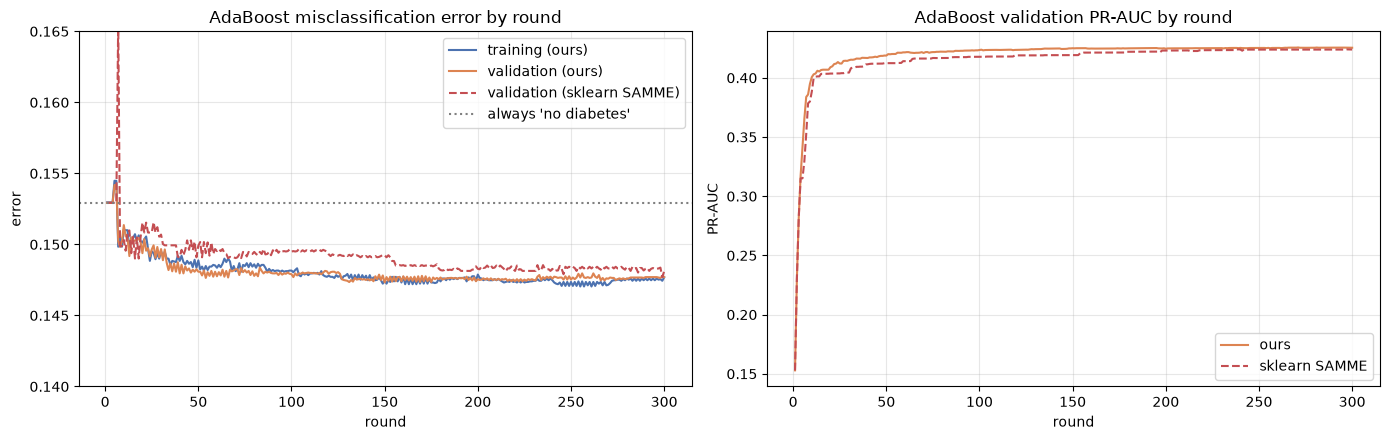

,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
AdaBoost from scratch (300 stumps),2.1896,0.4254,0.0959,0.8807,0.2728,0.4166,0.8168,0.4405,0.1052,16798,12359,628,4637


In [20]:
sk_stumps = [(int(e.tree_.feature[0]), float(e.tree_.threshold[0])) for e in ada_sk.estimators_]
gini_stumps = [(s.feature, s.threshold) for s in ada_gini.stumps]
n_common = min(len(sk_stumps), len(gini_stumps))
same_stumps = sum(a[0] == b[0] and np.isclose(a[1], b[1]) for a, b in zip(sk_stumps, gini_stumps))
print(f"Gini-stump AdaBoost vs sklearn: same stump in {same_stumps} of {n_common} rounds")

sk_staged_train = np.array([(p == ys).mean() for p in ada_sk.staged_predict(xs)])
sk_staged_val = np.array([(p == y_val).mean() for p in ada_sk.staged_predict(x_val_np)])
F_gini_train = adaboost_scores(ada_gini, xs)
gini_staged_train = ((F_gini_train > 0).astype(int) == ys).mean(axis=1)
assert same_stumps == n_common == len(sk_stumps)
assert np.array_equal(gini_staged_train, sk_staged_train)
assert np.allclose(ada_gini.errors, ada_sk.estimator_errors_[: len(ada_gini.errors)])

F_train, F_val = adaboost_scores(ada_ours, xs), adaboost_scores(ada_ours, x_val_np)
err_train = 1 - ((F_train > 0).astype(int) == ys).mean(axis=1)
err_val = 1 - ((F_val > 0).astype(int) == y_val).mean(axis=1)
ap_val_stage = np.array([average_precision_score(y_val, f) for f in F_val])
sk_ap_stage = np.array([average_precision_score(y_val, d) for d in ada_sk.staged_decision_function(x_val_np)])
final_gap = abs(err_val[-1] - (1 - sk_staged_val[-1]))
assert final_gap < 0.005, final_gap
print(f"Final validation error: ours (error stumps) {err_val[-1]:.4f}, sklearn {1 - sk_staged_val[-1]:.4f}; "
      f"validation PR-AUC ours {ap_val_stage[-1]:.4f}, sklearn {sk_ap_stage[-1]:.4f}")
print(f"Majority-class error (always 'no diabetes'): {y_val.mean():.4f}")

rounds = np.arange(1, len(err_train) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(rounds, err_train, color=BLUE, label="training (ours)")
axes[0].plot(rounds, err_val, color=ORANGE, label="validation (ours)")
axes[0].plot(np.arange(1, len(sk_staged_val) + 1), 1 - sk_staged_val, color=RED, linestyle="--",
             label="validation (sklearn SAMME)")
axes[0].axhline(y_val.mean(), color="grey", linestyle=":", label="always 'no diabetes'")
axes[0].set(title="AdaBoost misclassification error by round", xlabel="round", ylabel="error", ylim=(0.14, 0.165))
axes[0].legend()
axes[1].plot(rounds, ap_val_stage, color=ORANGE, label="ours")
axes[1].plot(np.arange(1, len(sk_ap_stage) + 1), sk_ap_stage, color=RED, linestyle="--", label="sklearn SAMME")
axes[1].set(title="AdaBoost validation PR-AUC by round", xlabel="round", ylabel="PR-AUC")
axes[1].legend()
plt.tight_layout()
plt.show()

evaluate(f"AdaBoost from scratch ({len(ada_ours.stumps)} stumps)", expit(2 * F_val[-1]),
         expit(2 * adaboost_scores(ada_ours, x_test_np)[-1]), t_ada, SCRATCH_RESULTS)

### Where the weight goes

After each round the misclassified rows gain weight, so the weight piles up on rows the stumps keep getting
wrong. Below: the share of the total weight held by the 1 %, 5 % and 10 % heaviest rows, and — after the
last round — who those rows are. "Risk" is notebook 01's logistic-regression probability, used only to
describe the rows.

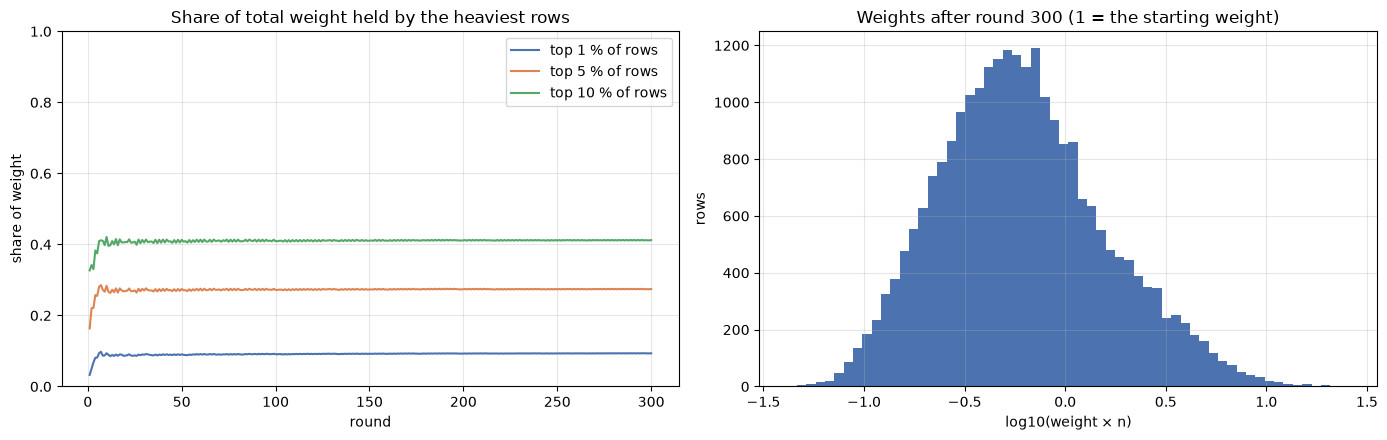

rows  share of rows  share of weight  weight per row (x average)
diabetic     risk                                                                           
diabetic     risk < 0.10     518         0.0207           0.1501                      7.2439
             0.10-0.30      1674         0.0670           0.2288                      3.4176
             risk >= 0.30   1632         0.0653           0.1208                      1.8511
not diabetic risk < 0.10   12126         0.4850           0.1544                      0.3184
             0.10-0.30      6819         0.2728           0.2153                      0.7892
             risk >= 0.30   2231         0.0892           0.1305                      1.4627

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for col, (label, color) in enumerate([("top 1 %", BLUE), ("top 5 %", ORANGE), ("top 10 %", GREEN)]):
    axes[0].plot(rounds, ada_ours.top_weight_share[:, col], color=color, label=f"{label} of rows")
axes[0].set(title="Share of total weight held by the heaviest rows", xlabel="round", ylabel="share of weight",
            ylim=(0, 1))
axes[0].legend()
w_final = ada_ours.final_weights
axes[1].hist(np.log10(w_final * len(w_final)), bins=60, color=BLUE)
axes[1].set(title=f"Weights after round {len(ada_ours.stumps)} (1 = the starting weight)",
            xlabel="log10(weight × n)", ylabel="rows")
plt.tight_layout()
plt.show()

risk = pos_proba(logistic, pd.DataFrame(xs, columns=FEATURES))
band = pd.cut(risk, [0, 0.1, 0.3, 1.0], labels=["risk < 0.10", "0.10-0.30", "risk >= 0.30"])
who = (pd.DataFrame({"diabetic": np.where(ys == 1, "diabetic", "not diabetic"), "risk": band, "w": w_final})
       .groupby(["diabetic", "risk"], observed=True)["w"].agg(rows="size", weight="sum"))
who["share of rows"] = who["rows"] / who["rows"].sum()
who["share of weight"] = who["weight"] / who["weight"].sum()
who["weight per row (x average)"] = who["share of weight"] / who["share of rows"]
who.drop(columns="weight")

**Observation: AdaBoost from scratch matches scikit-learn, and its weights end up on the people the
survey describes badly.**
* **Exact check:** with Gini stumps our AdaBoost picks **the same stump as scikit-learn in all 300 rounds**,
  gives identical staged training predictions and identical weighted errors. This confirms that SAMME's
  α = ln((1−ε)/ε) and our α = ½ ln((1−ε)/ε) produce the same normalised weights and the same sign of F.
* **Textbook version (error stumps):** final validation error 0.148 vs scikit-learn's 0.148, validation
  PR-AUC 0.425 vs 0.424 — similar, as expected.
* **Misclassification error is the wrong yardstick here.** It falls only from 0.153 (always "no diabetes")
  to about 0.148, because at the sign(F) = 0 cut-off (probability 0.5) the model rarely predicts diabetes.
  PR-AUC shows the real progress: from 0.15 after one stump to 0.40 after about 10 rounds and 0.425 after
  300. The early spike in error (rounds 5–7) is AdaBoost temporarily voting "diabetes" for a large group
  before later stumps correct it.
* **Weights:** after about 10 rounds the heaviest 1 % of rows hold 9 % of the weight and the heaviest
  10 % hold 41 %; the shares then stay flat. The weight sits on **contradictions**: diabetic people whom
  logistic regression rates as low risk (< 0.10) are 2.1 % of the rows but carry 15 % of the weight
  (7.2× the average row), while non-diabetic low-risk people (49 % of rows) carry 15 % (0.3× average).
  Non-diabetic people with a high-risk profile also gain weight (1.5×).
* That is AdaBoost's known weakness with **label noise**: a diabetic respondent whose survey answers look
  healthy is not a pattern that more stumps can learn, yet AdaBoost keeps up-weighting such rows.
* **Probabilities:** our p = 1/(1 + e^(−2F)) gives a Brier score of 0.105 on test. scikit-learn's
  AdaBoost `predict_proba` is a softmax of the normalised vote, not a calibrated probability: on the full
  data (Section 3.3) its Brier score is 0.172 and its F2 threshold is 0.40, against about 0.10 for every
  other model.

## 3.2 Gradient boosting from scratch (log-loss)

Gradient boosting builds an additive model $F_M(x) = F_0 + \nu \sum_m f_m(x)$ of the **log-odds**, with
$p = \sigma(F)$. For the log-loss $L = -[y\log p + (1-y)\log(1-p)]$ the negative gradient with respect to
$F$ is simply the residual $\;r_i = y_i - p_i$. Each round:

1. $F_0 = \log\frac{\bar y}{1 - \bar y}$ (the log-odds of the prevalence);
2. compute the residuals $r_i = y_i - \sigma(F_{m-1}(x_i))$;
3. fit a small **regression tree** (depth 3) to $r$ — this chooses the regions $R_{jm}$;
4. **line search** per leaf: one Newton step on the log-loss,
   $\gamma_{jm} = \dfrac{\sum_{i \in R_{jm}} r_i}{\sum_{i \in R_{jm}} p_i(1-p_i)}$;
5. update with **shrinkage** $\nu$ (learning rate): $F_m = F_{m-1} + \nu\, \gamma_{j m}$ for rows in leaf $j$.

The base learner is scikit-learn's `DecisionTreeRegressor` (squared-error criterion; scikit-learn 1.9 maps GradientBoosting's `friedman_mse` to it); everything else is
written here. Runs on the 25,000-row sample with 150 rounds, depth 3, $\nu = 0.1$. For comparison we also
run (a) a **fixed step** (keep the tree's mean residual, no line search) and (b) no shrinkage ($\nu = 1$).

Training rows: max |ours - GradientBoostingClassifier| over all 150 stages = 2.6e-15
Identical trees (features and thresholds): 146 of 150; first difference at round 74
  node 9: ours splits on BMI <= 44.5, sklearn on Age <= 8.5 (5 training rows in the node, same training predictions)
Validation rows after 150 rounds: identical for 99.98%, max difference 0.039, PR-AUC difference 1.1e-05  (fit: ours 1.8 s, sklearn 1.9 s)


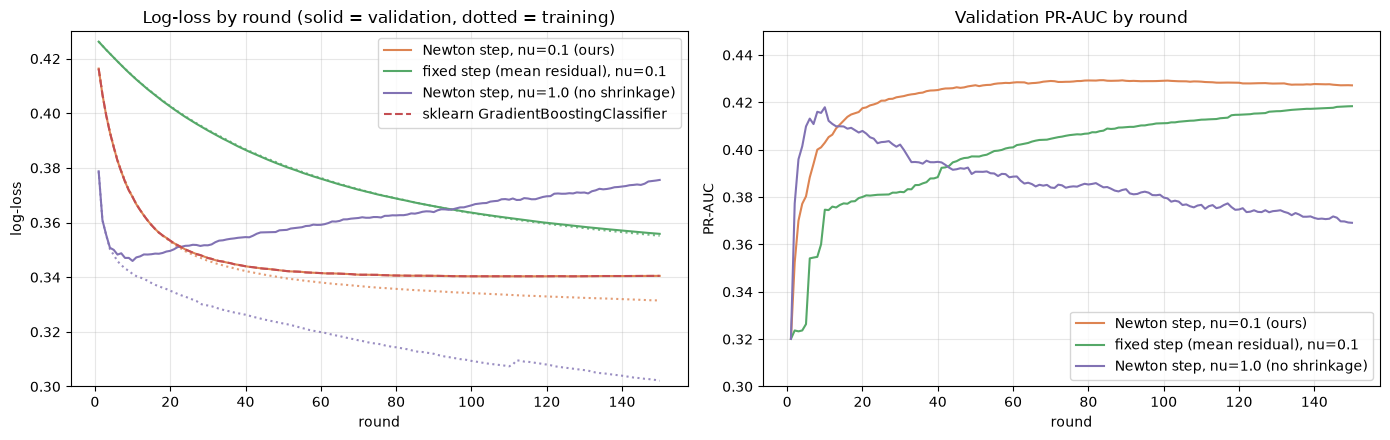

,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"Gradient boosting from scratch (150 trees, depth 3)",1.8165,0.4272,0.0869,0.9035,0.2648,0.4096,0.819,0.4456,0.1048,15949,13208,508,4757


In [22]:
class GBModel(NamedTuple):
    """A fitted from-scratch gradient-boosting classifier."""

    f0: float  # initial log-odds
    learning_rate: float
    trees: list[DecisionTreeRegressor]
    leaf_steps: list[FloatArray]  # step for every node id of each tree (only leaves are used)


def gb_fit(x: FloatArray, y: IntArray, n_trees: int, learning_rate: float, max_depth: int = 3,
           leaf_step: Literal["newton", "mean"] = "newton", seed: int = RANDOM_STATE) -> GBModel:
    """Gradient boosting for the log-loss with regression trees.

    Args:
        x: Training features.
        y: 0/1 labels.
        n_trees: Number of boosting rounds.
        learning_rate: Shrinkage factor nu.
        max_depth: Depth of each regression tree.
        leaf_step: ``"newton"`` (per-leaf line search) or ``"mean"`` (the tree's mean residual).
        seed: ``random_state`` of the trees (only breaks exact ties).

    Returns:
        The fitted model.
    """
    f0 = float(np.log(y.mean() / (1 - y.mean())))
    raw = np.full(len(y), f0)
    rng = np.random.RandomState(seed)
    trees, steps = [], []
    for _ in range(n_trees):
        p = expit(raw)
        residual = y - p  # negative gradient of the log-loss w.r.t. the log-odds
        tree = DecisionTreeRegressor(criterion="squared_error", max_depth=max_depth, random_state=rng).fit(x, residual)
        leaf = tree.apply(x)
        if leaf_step == "newton":
            n_nodes = tree.tree_.node_count
            num = np.bincount(leaf, weights=residual, minlength=n_nodes)
            den = np.bincount(leaf, weights=p * (1 - p), minlength=n_nodes)
            step = np.divide(num, den, out=np.zeros(n_nodes), where=den > 1e-150)
        else:
            step = tree.tree_.value[:, 0, 0].copy()
        raw += learning_rate * step[leaf]
        trees.append(tree)
        steps.append(step)
    return GBModel(f0, learning_rate, trees, steps)


def gb_staged_raw(model: GBModel, x: FloatArray) -> FloatArray:
    """Staged log-odds F_m(x) for m = 1..M, shape (M, n)."""
    updates = np.vstack([s[t.apply(x)] for t, s in zip(model.trees, model.leaf_steps)])
    return model.f0 + model.learning_rate * np.cumsum(updates, axis=0)


N_GB, LR_GB, DEPTH_GB = 150, 0.1, 3
gb_ours, t_gb = timed(lambda: gb_fit(xs, ys, N_GB, LR_GB, DEPTH_GB))
gb_sk, t_gb_sk = timed(lambda: GradientBoostingClassifier(
    n_estimators=N_GB, learning_rate=LR_GB, max_depth=DEPTH_GB, random_state=RANDOM_STATE).fit(xs, ys))

p_ours_train = expit(gb_staged_raw(gb_ours, xs))
p_sk_train = np.vstack([p[:, 1] for p in gb_sk.staged_predict_proba(xs)])
p_ours_val = expit(gb_staged_raw(gb_ours, x_val_np))
p_sk_val = np.vstack([p[:, 1] for p in gb_sk.staged_predict_proba(x_val_np)])
train_diff = float(np.abs(p_ours_train - p_sk_train).max())
same_tree = [np.array_equal(t.tree_.feature, s.tree_.feature) and np.allclose(t.tree_.threshold, s.tree_.threshold)
             for t, s in zip(gb_ours.trees, gb_sk.estimators_[:, 0])]
first_diff = next((m for m, same in enumerate(same_tree) if not same), None)
val_gap = np.abs(p_ours_val[-1] - p_sk_val[-1])
ap_gap = abs(average_precision_score(y_val, p_ours_val[-1]) - average_precision_score(y_val, p_sk_val[-1]))
assert train_diff < 1e-9, train_diff  # identical fit to the training rows at every stage
assert np.mean(val_gap > 1e-9) < 0.05 and ap_gap < 0.002
print(f"Training rows: max |ours - GradientBoostingClassifier| over all {N_GB} stages = {train_diff:.1e}")
print(f"Identical trees (features and thresholds): {sum(same_tree)} of {N_GB}; first difference at round "
      f"{'none' if first_diff is None else first_diff + 1}")
if first_diff is not None:
    t_o, t_s = gb_ours.trees[first_diff].tree_, gb_sk.estimators_[first_diff, 0].tree_
    node = int(np.flatnonzero((t_o.feature != t_s.feature) | ~np.isclose(t_o.threshold, t_s.threshold))[0])
    print(f"  node {node}: ours splits on {FEATURES[t_o.feature[node]]} <= {t_o.threshold[node]}, sklearn on "
          f"{FEATURES[t_s.feature[node]]} <= {t_s.threshold[node]} ({t_o.n_node_samples[node]} training rows in "
          f"the node, same training predictions)")
print(f"Validation rows after {N_GB} rounds: identical for {np.mean(val_gap <= 1e-9):.2%}, max difference "
      f"{val_gap.max():.3f}, PR-AUC difference {ap_gap:.1e}  (fit: ours {t_gb:.1f} s, sklearn {t_gb_sk:.1f} s)")

variants = {f"Newton step, nu={LR_GB} (ours)": gb_ours,
            f"fixed step (mean residual), nu={LR_GB}": gb_fit(xs, ys, N_GB, LR_GB, DEPTH_GB, leaf_step="mean"),
            "Newton step, nu=1.0 (no shrinkage)": gb_fit(xs, ys, N_GB, 1.0, DEPTH_GB)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (name, model), color in zip(variants.items(), [ORANGE, GREEN, PURPLE]):
    p_tr, p_va = expit(gb_staged_raw(model, xs)), expit(gb_staged_raw(model, x_val_np))
    stage = np.arange(1, N_GB + 1)
    axes[0].plot(stage, [log_loss(ys, p) for p in p_tr], color=color, linestyle=":", alpha=0.8)
    axes[0].plot(stage, [log_loss(y_val, p) for p in p_va], color=color, label=name)
    axes[1].plot(stage, [average_precision_score(y_val, p) for p in p_va], color=color, label=name)
axes[0].plot(np.arange(1, N_GB + 1), [log_loss(y_val, p) for p in p_sk_val], color=RED, linestyle="--",
             label="sklearn GradientBoostingClassifier")
axes[0].set(title="Log-loss by round (solid = validation, dotted = training)", xlabel="round",
            ylabel="log-loss", ylim=(0.30, 0.43))
axes[0].legend()
axes[1].set(title="Validation PR-AUC by round", xlabel="round", ylabel="PR-AUC", ylim=(0.30, 0.45))
axes[1].legend()
plt.tight_layout()
plt.show()

evaluate(f"Gradient boosting from scratch ({N_GB} trees, depth {DEPTH_GB})", p_ours_val[-1],
         expit(gb_staged_raw(gb_ours, x_test_np)[-1]), t_gb, SCRATCH_RESULTS)

**Observation: gradient boosting from scratch reproduces scikit-learn, and the plots show why the line
search and shrinkage matter.**
* **Check:** on the 25,000 training rows our staged probabilities equal `GradientBoostingClassifier`'s to
  3 × 10⁻¹⁵ at all 150 stages. 146 of the 150 trees are identical. At round 74 one node of 5 training rows
  can be split by `BMI <= 44.5` or `Age <= 8.5` with exactly the same result on those 5 rows; last-bit
  rounding in the residuals decides, and the two implementations choose differently. Both rules fit the
  training rows identically, but they route a few unseen people differently: 99.98 % of validation
  probabilities are identical, the largest difference is 0.039, and validation PR-AUC differs by 1 × 10⁻⁵.
* **Newton step vs fixed step:** the residual y − p is on the probability scale, while F is on the
  log-odds scale. The Newton step divides by p(1−p) ≈ 0.13, so it is about 7× larger. With a fixed step
  (the tree's mean residual) the validation log-loss is still falling after 150 rounds (0.356 vs 0.340 with
  Newton) — the same model, just much slower.
* **Shrinkage:** with ν = 1 (no shrinkage) the validation log-loss is best after about 10 rounds and then
  rises while the training log-loss keeps falling — overfitting. With ν = 0.1 the validation loss levels
  off at 0.340 after about 80 rounds and stays there. A smaller learning rate costs more rounds but
  generalises better.
* On the test set the 150-round model trained on 25,000 rows already reaches PR-AUC 0.446.

## 3.3 The library models on the full data

Now on all 160,631 training rows:

* scikit-learn **AdaBoost** (SAMME, 300 stumps) for the comparison table;
* scikit-learn **GradientBoostingClassifier** (exact split search, single core): 400 rounds, depth 3,
  $\nu = 0.1$; the number of rounds is chosen on the validation log-loss with `staged_predict_proba`;
* scikit-learn **HistGradientBoostingClassifier** (features binned into ≤ 255 bins, much faster), with its
  built-in early stopping on an internal 10 % of the training rows;
* **XGBoost** (as in notebook 01), exploring the learning rate, depth and number of trees with **early
  stopping on our validation set** (stop when the validation log-loss has not improved for 50 rounds).

In [23]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    ada_full, t_ada_full = timed(lambda: AdaBoostClassifier(
        DecisionTreeClassifier(max_depth=1), n_estimators=N_ROUNDS, random_state=RANDOM_STATE, **ada_kwargs
    ).fit(x_train, y_train))
display(evaluate(f"AdaBoost (sklearn, {N_ROUNDS} stumps)", pos_proba(ada_full, x_val), pos_proba(ada_full, x_test),
                 t_ada_full))

gb_full, t_gb_full = timed(lambda: GradientBoostingClassifier(
    n_estimators=400, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE).fit(x_train, y_train))
val_stage = [p[:, 1] for p in gb_full.staged_predict_proba(x_val)]
val_loss = np.array([log_loss(y_val, p) for p in val_stage])
best_n = int(np.argmin(val_loss)) + 1
test_best = next(p[:, 1] for i, p in enumerate(gb_full.staged_predict_proba(x_test), 1) if i == best_n)
train_loss = [log_loss(y_train, p[:, 1]) for p in gb_full.staged_predict_proba(x_train)]
print(f"sklearn GradientBoosting: best validation log-loss {val_loss.min():.4f} at {best_n} rounds "
      f"(400 rounds: {val_loss[-1]:.4f}); fit {t_gb_full:.0f} s")
display(evaluate(f"Gradient boosting (sklearn, {best_n} trees)", val_stage[best_n - 1], test_best, t_gb_full))

hgb, t_hgb = timed(lambda: HistGradientBoostingClassifier(
    max_iter=1000, learning_rate=0.1, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
    random_state=RANDOM_STATE).fit(x_train, y_train))
print(f"HistGradientBoosting stopped after {hgb.n_iter_} iterations")
evaluate(f"HistGradientBoosting ({hgb.n_iter_} iters)", pos_proba(hgb, x_val), pos_proba(hgb, x_test), t_hgb)

,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"AdaBoost (sklearn, 300 stumps)",9.6494,0.4259,0.3982,0.8746,0.2802,0.4244,0.8185,0.4434,0.1723,17327,11830,660,4605


sklearn GradientBoosting: best validation log-loss 0.3372 at 381 rounds (400 rounds: 0.3372); fit 32 s


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"Gradient boosting (sklearn, 381 trees)",31.7195,0.4371,0.1048,0.876,0.2817,0.4263,0.8226,0.4548,0.104,17396,11761,653,4612


HistGradientBoosting stopped after 81 iterations


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
HistGradientBoosting (81 iters),1.3395,0.4354,0.1068,0.872,0.2806,0.4245,0.8213,0.4526,0.1043,17385,11772,674,4591


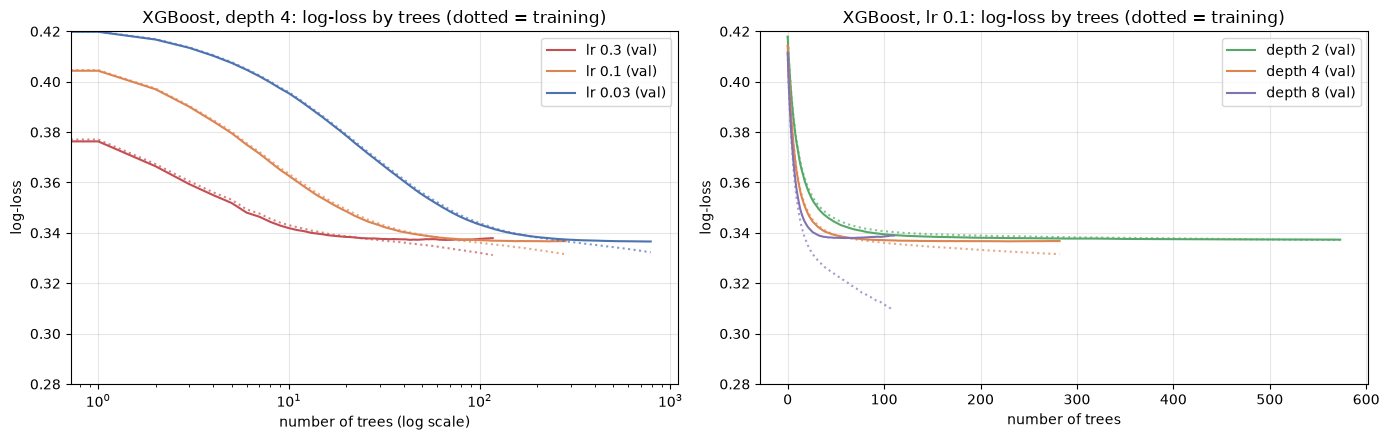

,learning_rate,max_depth,best n_trees,val log-loss,val PR-AUC,fit (s)
0,0.30,4,68,0.3372,0.4380,0.4084
1,0.10,4,233,0.3366,0.4385,0.8753
2,0.03,4,739,0.3366,0.4399,2.6770
3,0.10,2,524,0.3373,0.4370,1.5538
4,0.10,3,270,0.3370,0.4382,0.9880
5,0.10,6,96,0.3371,0.4376,0.6564
6,0.10,8,61,0.3379,0.4336,0.5640


,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"XGBoost (lr 0.03, depth 4, 739 trees)",2.677,0.4399,0.1165,0.8613,0.29,0.4339,0.8225,0.4551,0.104,18054,11103,730,4535


In [24]:
def fit_xgb_early(learning_rate: float, max_depth: int) -> tuple[XGBClassifier, float]:
    """XGBoost with early stopping on the validation log-loss.

    Args:
        learning_rate: Shrinkage per tree.
        max_depth: Maximum tree depth.

    Returns:
        The fitted model (predictions use the best iteration) and its fit time.
    """
    model = make_xgb(n_estimators=5000, learning_rate=learning_rate, max_depth=max_depth,
                     early_stopping_rounds=50)
    return timed(lambda: model.fit(x_train, y_train, eval_set=[(x_train, y_train), (x_val, y_val)], verbose=False))


XGB_GRID = [(0.3, 4), (0.1, 4), (0.03, 4), (0.1, 2), (0.1, 3), (0.1, 6), (0.1, 8)]
xgb_fits, xgb_rows = {}, []
for lr_x, depth_x in XGB_GRID:
    model, seconds = fit_xgb_early(lr_x, depth_x)
    xgb_fits[(lr_x, depth_x)] = (model, seconds)
    xgb_rows.append({"learning_rate": lr_x, "max_depth": depth_x, "best n_trees": model.best_iteration + 1,
                     "val log-loss": model.best_score, "val PR-AUC": average_precision_score(y_val, pos_proba(model, x_val)),
                     "fit (s)": seconds})
xgb_df = pd.DataFrame(xgb_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (lr_x, depth_x), color in zip(XGB_GRID[:3], [RED, ORANGE, BLUE]):
    hist = xgb_fits[(lr_x, depth_x)][0].evals_result()
    axes[0].plot(hist["validation_1"]["logloss"], color=color, label=f"lr {lr_x} (val)")
    axes[0].plot(hist["validation_0"]["logloss"], color=color, linestyle=":", alpha=0.7)
axes[0].set(xscale="log", title="XGBoost, depth 4: log-loss by trees (dotted = training)",
            xlabel="number of trees (log scale)", ylabel="log-loss", ylim=(0.28, 0.42))
axes[0].legend()
for (lr_x, depth_x), color in zip([(0.1, 2), (0.1, 4), (0.1, 8)], [GREEN, ORANGE, PURPLE]):
    hist = xgb_fits[(lr_x, depth_x)][0].evals_result()
    axes[1].plot(hist["validation_1"]["logloss"], color=color, label=f"depth {depth_x} (val)")
    axes[1].plot(hist["validation_0"]["logloss"], color=color, linestyle=":", alpha=0.7)
axes[1].set(title="XGBoost, lr 0.1: log-loss by trees (dotted = training)", xlabel="number of trees",
            ylabel="log-loss", ylim=(0.28, 0.42))
axes[1].legend()
plt.tight_layout()
plt.show()
display(xgb_df)

best_cfg = tuple(xgb_df.loc[xgb_df["val PR-AUC"].idxmax(), ["learning_rate", "max_depth"]])
best_cfg = (float(best_cfg[0]), int(best_cfg[1]))
xgb_best, t_xgb = xgb_fits[best_cfg]
evaluate(f"XGBoost (lr {best_cfg[0]}, depth {best_cfg[1]}, {xgb_best.best_iteration + 1} trees)",
         pos_proba(xgb_best, x_val), pos_proba(xgb_best, x_test), t_xgb)

**Observation: on the full data every boosted model lands in the same place; tuning matters much less
than choosing boosting at all.**
* **AdaBoost** (300 stumps): test PR-AUC 0.443, but a Brier score of 0.172 because its probabilities are
  not calibrated (see 3.1).
* **sklearn GradientBoosting** (depth 3, ν = 0.1): validation log-loss 0.3372, best at 381 of 400 rounds
  (the loss at 400 rounds is the same to four decimals); test PR-AUC 0.455. It is the slowest model here (32 s, single core,
  exact split search).
* **HistGradientBoosting:** its internal early stopping stops after 81 iterations; test PR-AUC 0.453 in
  1.3 s — 25× faster than `GradientBoostingClassifier` for a 0.002 lower PR-AUC.
* **XGBoost:**
  * *Learning rate:* lower rates need more trees (68 trees at 0.3, 233 at 0.1, 739 at 0.03) and end
    marginally better (validation log-loss 0.3372 → 0.3366; PR-AUC 0.438 → 0.440).
  * *Depth:* depth 2 needs 524 trees; depth 8 overfits within 61 trees (training log-loss keeps dropping
    while validation turns up) and is the worst setting (validation PR-AUC 0.434).
  * *Early stopping* finds the number of trees for each setting automatically, so `n_estimators` stops
    being a parameter to tune.
  * All seven settings are within 0.006 validation PR-AUC of each other. The best (learning rate 0.03,
    depth 4, 739 trees) reaches **test PR-AUC 0.455**, ROC-AUC 0.823, recall 0.861, precision 0.290,
    Brier 0.104.
* Note: early stopping and the F2 threshold both use the validation set; the test set is still untouched.

# 4. Comparison and link to the app

## 4.1 The app recipe

`app/ml/train.py` (and notebook 01, Section 7) trains XGBoost with notebook 01's settings, **class-weighted**
(`scale_pos_weight` = negatives / positives), wrapped in 3-fold **isotonic calibration**, and picks the F2
threshold on validation. We refit that recipe here on the same split so it appears in the table, then compare
it with the metrics saved next to the app's model in `models/risk_model.meta.json`.

In [25]:
pos_weight = (1 - prevalence) / prevalence
app_recipe, t_app = timed(lambda: CalibratedClassifierCV(make_xgb(scale_pos_weight=pos_weight), method="isotonic",
                                                         cv=3).fit(x_train, y_train))
evaluate("XGBoost, app recipe (class-weighted + isotonic)", pos_proba(app_recipe, x_val),
         pos_proba(app_recipe, x_test), t_app)

,fit time (s),val PR-AUC,threshold,recall,precision,F1,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
"XGBoost, app recipe (class-weighted + isotonic)",2.3918,0.4378,0.1075,0.8824,0.2773,0.422,0.8224,0.4529,0.1042,17050,12107,619,4646


In [26]:
if META_PATH is None:
    print("models/risk_model.meta.json not found (e.g. on Colab): app-model check skipped.")
else:
    meta = json.loads(META_PATH.read_text())
    ours = RESULTS["XGBoost, app recipe (class-weighted + isotonic)"]
    saved = meta["test"]
    (tn, fp), (fn, tp) = saved["confusion"]
    check = pd.DataFrame({
        "saved app model (meta.json)": [meta["training_rows"], meta["prevalence"], saved["threshold"],
                                         saved["recall"], saved["precision"], saved["f1"], saved["roc_auc"],
                                         saved["pr_auc"], saved["brier"], tn, fp, fn, tp],
        "this notebook": [len(x_train), prevalence, ours["threshold"], ours["recall"], ours["precision"],
                          ours["F1"], ours["ROC-AUC"], ours["PR-AUC"], ours["Brier"], ours["TN"], ours["FP"],
                          ours["FN"], ours["TP"]],
    }, index=["training rows", "prevalence", "threshold", "recall", "precision", "F1", "ROC-AUC", "PR-AUC",
              "Brier", "TN", "FP", "FN", "TP"])
    check["difference"] = check["this notebook"] - check["saved app model (meta.json)"]
    print(f"App model {meta['version']} ({meta['model_name']}), trained {meta['trained_at'][:10]}")
    display(check)
    assert meta["training_rows"] == len(x_train) and abs(meta["prevalence"] - prevalence) < 1e-12
    metric_gap = check.loc[["recall", "precision", "F1", "ROC-AUC", "PR-AUC", "Brier"], "difference"].abs().max()
    print(f"Largest metric difference: {metric_gap:.2e}")

App model risk-20261114-204228 (gradient_boosting), trained 2026-11-14


,saved app model (meta.json),this notebook,difference
training rows,160631.0000,160631.0000,0.0
prevalence,0.1529,0.1529,0.0
threshold,0.1075,0.1075,0.0
recall,0.8824,0.8824,0.0
precision,0.2773,0.2773,0.0
F1,0.4220,0.4220,0.0
ROC-AUC,0.8224,0.8224,0.0
PR-AUC,0.4529,0.4529,0.0
Brier,0.1042,0.1042,0.0
TN,17050.0000,17050.0000,0.0


Largest metric difference: 0.00e+00


**Observation: the app model is reproduced exactly.** Refitting the app recipe in this notebook gives the
same training rows (160,631), prevalence, F2 threshold (0.1075) and test metrics as
`models/risk_model.meta.json` — recall 0.882, precision 0.277, F1 0.422, ROC-AUC 0.822, PR-AUC 0.453,
Brier 0.104 and the confusion matrix [[17,050, 12,107], [619, 4,646]] — with every difference exactly 0.
That confirms the split, de-duplication and seed are the app's, so all rows of the Section 4 table are
directly comparable with the app's model. (On another machine or with other library versions, for
example on Colab, XGBoost's floating-point results can differ slightly and the numbers may move in the
third decimal.)

## 4.2 One table, one test set

All library models, trained on the same 160,631 rows, thresholded by F2 on the same validation rows and
scored on the same 34,422 test rows. **Fit time** is wall-clock on the machine that ran this notebook
(10 CPU cores; random forest, bagging and XGBoost use all cores, scikit-learn's AdaBoost and
GradientBoosting use one), so compare orders of magnitude, not exact seconds. To show which differences
are larger than the noise of one test set, the test PR-AUC gets a 95 % **paired bootstrap** interval
(1,000 resamples of the test rows, the same resamples for every model), and the difference to logistic
regression gets its own interval.

In [27]:
table = pd.DataFrame.from_dict(RESULTS, orient="index").sort_values("PR-AUC", ascending=False)

rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
boot = pd.DataFrame({name: [average_precision_score(y_test[i], TEST_PROBA[name][i]) for i in boot_idx]
                     for name in table.index})
baseline = "Logistic regression (notebook 01)"
table["PR-AUC 95% CI"] = [f"{boot[n].quantile(0.025):.3f}-{boot[n].quantile(0.975):.3f}" for n in table.index]
diff = boot.sub(boot[baseline], axis=0)
table["PR-AUC vs LR (95% CI)"] = [
    f"{table.loc[n, 'PR-AUC'] - table.loc[baseline, 'PR-AUC']:+.3f} ({diff[n].quantile(0.025):+.3f}, "
    f"{diff[n].quantile(0.975):+.3f})" for n in table.index]
columns = ["recall", "precision", "F1", "ROC-AUC", "PR-AUC", "PR-AUC 95% CI", "PR-AUC vs LR (95% CI)", "Brier",
           "threshold", "TN", "FP", "FN", "TP", "fit time (s)"]
display(table[columns].style.format({"fit time (s)": "{:.1f}"}, precision=3))

,recall,precision,F1,ROC-AUC,PR-AUC,PR-AUC 95% CI,PR-AUC vs LR (95% CI),Brier,threshold,TN,FP,FN,TP,fit time (s)
"XGBoost (lr 0.03, depth 4, 739 trees)",0.861,0.290,0.434,0.823,0.455,0.440-0.469,"+0.035 (+0.028, +0.042)",0.104,0.116,18054,11103,730,4535,2.7
"Gradient boosting (sklearn, 381 trees)",0.876,0.282,0.426,0.823,0.455,0.441-0.469,"+0.035 (+0.028, +0.041)",0.104,0.105,17396,11761,653,4612,31.7
Stacking (LR meta-model),0.839,0.301,0.443,0.822,0.453,0.438-0.467,"+0.033 (+0.026, +0.040)",0.105,0.100,18898,10259,850,4415,17.2
"XGBoost, app recipe (class-weighted + isotonic)",0.882,0.277,0.422,0.822,0.453,0.438-0.467,"+0.033 (+0.025, +0.040)",0.104,0.108,17050,12107,619,4646,2.4
HistGradientBoosting (81 iters),0.872,0.281,0.425,0.821,0.453,0.438-0.466,"+0.033 (+0.026, +0.039)",0.104,0.107,17385,11772,674,4591,1.3
Soft voting (LR + RF + XGB),0.879,0.278,0.423,0.821,0.450,0.436-0.464,"+0.030 (+0.025, +0.035)",0.105,0.109,17162,11995,638,4627,3.3
"Random forest (200 trees, leaf 20)",0.854,0.287,0.430,0.819,0.448,0.433-0.462,"+0.028 (+0.020, +0.035)",0.105,0.128,18002,11155,771,4494,3.6
"AdaBoost (sklearn, 300 stumps)",0.875,0.280,0.424,0.819,0.443,0.429-0.457,"+0.023 (+0.017, +0.030)",0.172,0.398,17327,11830,660,4605,9.6
"Bagging (200 trees, leaf 20)",0.868,0.273,0.415,0.813,0.437,0.422-0.451,"+0.017 (+0.009, +0.024)",0.106,0.107,16990,12167,696,4569,9.9
CART (pruned),0.844,0.276,0.416,0.803,0.420,0.406-0.434,"+0.000 (-0.007, +0.008)",0.107,0.127,17513,11644,819,4446,1.3


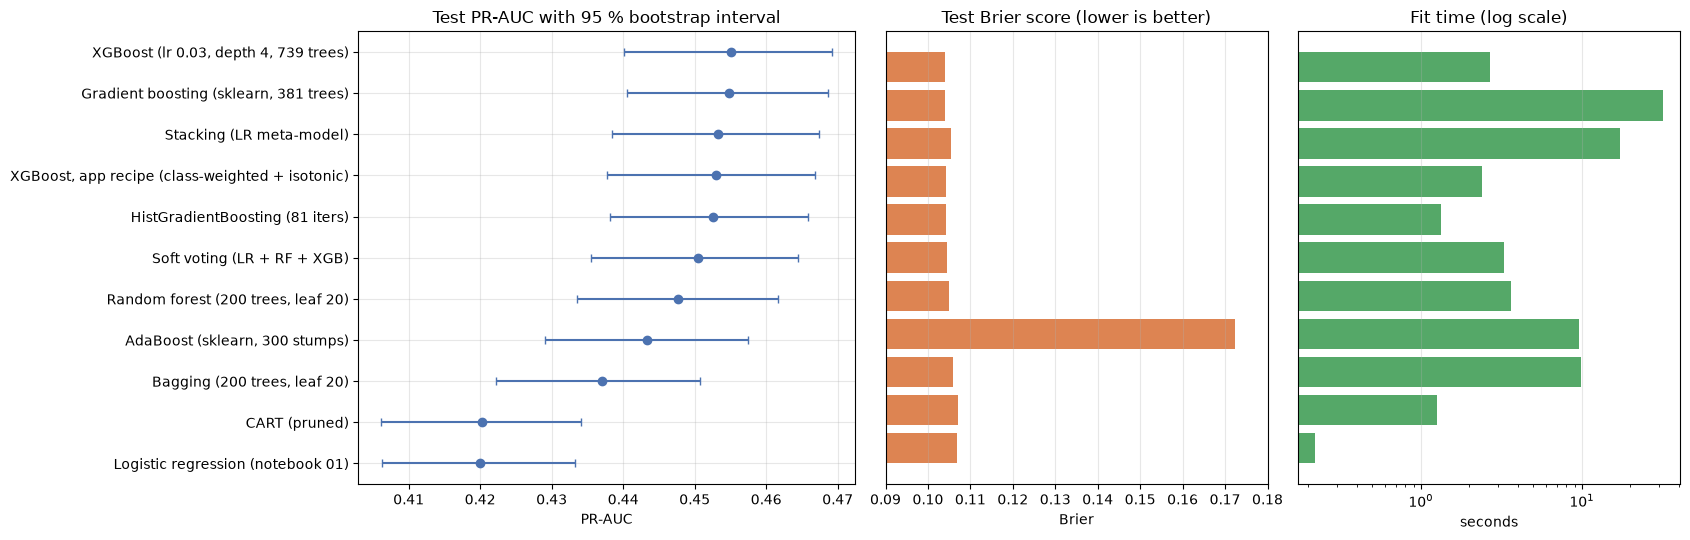

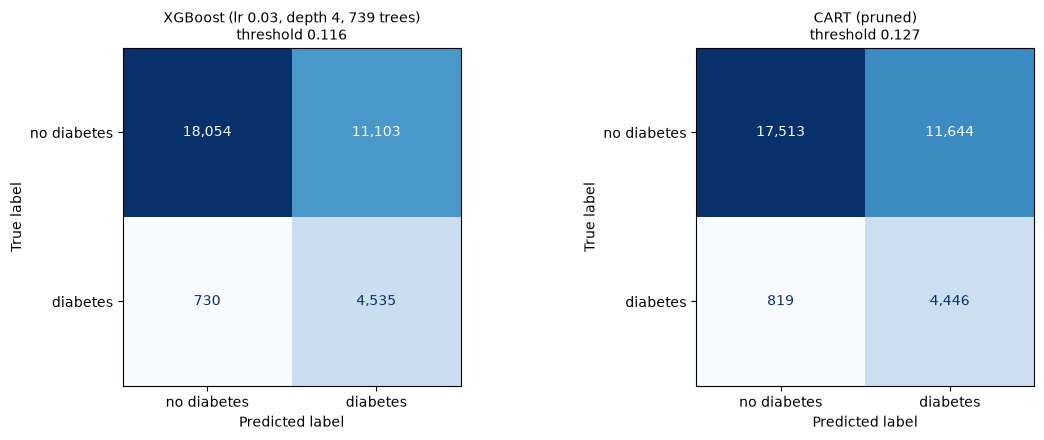

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
order = table.index[::-1]
lo = [boot[n].quantile(0.025) for n in order]
hi = [boot[n].quantile(0.975) for n in order]
axes[0].errorbar(table.loc[order, "PR-AUC"], order, fmt="o", color=BLUE, capsize=3,
                 xerr=[table.loc[order, "PR-AUC"] - lo, np.array(hi) - table.loc[order, "PR-AUC"]])
axes[0].set(title="Test PR-AUC with 95 % bootstrap interval", xlabel="PR-AUC")
axes[1].barh(order, table.loc[order, "Brier"], color=ORANGE)
axes[1].set(xlim=(0.09, 0.18), title="Test Brier score (lower is better)", xlabel="Brier", yticks=[])
axes[2].barh(order, table.loc[order, "fit time (s)"], color=GREEN)
axes[2].set(xscale="log", title="Fit time (log scale)", xlabel="seconds", yticks=[])
plt.tight_layout()
plt.show()

best_name = table.index[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, [best_name, "CART (pruned)"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (TEST_PROBA[name] >= RESULTS[name]["threshold"]).astype(int), display_labels=["no diabetes", "diabetes"],
        cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set_title(f"{name}\nthreshold {RESULTS[name]['threshold']:.3f}", fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

### From-scratch implementations (25,000-row training sample)

For completeness, the from-scratch models scored the same way on the same full validation and test sets.
They were trained on **15 % of the training rows**, so they are not competitors for the table above; they
show that the code works and that more data helps.

In [29]:
scratch_table = pd.DataFrame.from_dict(SCRATCH_RESULTS, orient="index")
scratch_table[["recall", "precision", "F1", "ROC-AUC", "PR-AUC", "Brier", "threshold", "TN", "FP", "FN", "TP",
               "fit time (s)"]].style.format({"fit time (s)": "{:.1f}"}, precision=3)

,recall,precision,F1,ROC-AUC,PR-AUC,Brier,threshold,TN,FP,FN,TP,fit time (s)
"CART from scratch (gini, depth 6)",0.890,0.255,0.396,0.798,0.400,0.108,0.103,15435,13722,579,4686,0.1
Bagging from scratch (100 trees),0.855,0.246,0.383,0.773,0.364,0.115,0.102,15386,13771,763,4502,3.1
AdaBoost from scratch (300 stumps),0.881,0.273,0.417,0.817,0.440,0.105,0.096,16798,12359,628,4637,2.2
"Gradient boosting from scratch (150 trees, depth 3)",0.904,0.265,0.410,0.819,0.446,0.105,0.087,15949,13208,508,4757,1.8


## 4.3 Conclusions

**Which approach wins, and by how much.** Gradient-boosted trees: XGBoost (test PR-AUC 0.455),
scikit-learn's GradientBoosting (0.455), stacking (0.453), the app's calibrated XGBoost (0.453) and
HistGradientBoosting (0.453) are all within 0.003 of each other, and their 95 % bootstrap intervals
overlap almost entirely. Against notebook 01's logistic regression (0.420) they gain **about +0.035
PR-AUC** (95 % interval +0.028 to +0.042) and +0.010 ROC-AUC (0.812 → 0.823). The random forest gains
+0.028, bagging +0.017, and the pruned single tree gains nothing (+0.000).

| | single tree (pruned) | bagging | random forest | voting / stacking | AdaBoost | gradient boosting / XGBoost |
|---|---|---|---|---|---|---|
| what it fixes | — | variance of deep trees | + correlation between trees | mixes model types | bias, with stumps | bias, with small trees |
| test PR-AUC | 0.420 | 0.437 | 0.448 | 0.450 / 0.453 | 0.443 | 0.455 |

**What the gain means for people.** At each model's F2 screening threshold, logistic regression flags
16,487 of the 34,422 test people and finds 4,578 of the 5,265 diabetic ones (precision 0.278); the best
XGBoost flags 15,638 and finds 4,535 (precision 0.290). That is 806 fewer false alarms for 43 fewer
cases found — a real but modest improvement.

**Is it worth the complexity?** Training cost is not the issue (XGBoost and HistGradientBoosting train in
1–3 s). The costs are transparency (logistic regression's coefficients can be read directly; 739 trees
cannot) and calibration (boosted models need checking, AdaBoost's scores are not probabilities at all).
For the app, the existing calibrated XGBoost is a reasonable choice and none of the alternatives here
is better by more than the noise of one test set: stacking and voting add training time without improving
PR-AUC, and tuning XGBoost further changed the test PR-AUC by +0.002. A team that values a fully
explainable model could use logistic regression and give up about 0.035 PR-AUC.

**Precision stays low.** Every model, at a screening threshold that finds 84–88 % of diabetic people, has
precision between 0.27 and 0.30: **roughly 7 of every 10 people flagged do not have diabetes.** That
comes from the data (self-reported survey answers, about 15 % prevalence, no glucose or HbA1c), not
from the choice of algorithm, and no ensemble here changes it. The model is a prompt to "consider a
check-up", never a diagnosis.

**Link to the app.** The app's risk model is reproduced exactly (Section 4.1). Its risk tier is
**information only**: it is stored for audit and shown to the practitioner. **None of these models changes
a glucose limit** — personal limits come from the threshold engine (cited ADA values plus bounded
adjustments), and readings within 5 % of a limit trigger the advisory regardless of any model.

**Departures and choices to note**
* From-scratch code ran on a stratified 25,000-row sample of the training split (15 %); library models on
  all 160,631 training rows. Both are scored on the same full validation and test sets.
* All models except the app recipe are trained **without class re-weighting**, so their Brier scores are
  comparable; the imbalance is handled by the F2 threshold.
* Bagging and gradient boosting use scikit-learn trees as base learners (the bagging and boosting loops
  are written here); the CART tree and AdaBoost's stumps are fully from scratch.
* scikit-learn ≥ 1.8 has no `algorithm` argument for AdaBoost (SAMME is the only algorithm); the notebook
  passes `algorithm="SAMME"` only when the installed version accepts it.
* The entropy tree and gradient-boosting checks allow for exact ties between features (explained in
  1.3 and 3.2); the Gini tree, bagging and AdaBoost checks are exact.
* HistGradientBoosting uses its own internal 10 % early-stopping split (works on every scikit-learn
  version); XGBoost early-stops on our validation set.

**Limitations.** BRFSS 2015 is a self-reported US telephone survey; results may not transfer to Indian
users without recalibration. One test set of 34,422 people: differences under about 0.01 PR-AUC are
within noise. Fit times are from one laptop and indicate orders of magnitude only. Performance per sex,
age and income group was not checked here and should be before any real use.

In [30]:
print(f"Notebook runtime: {time.perf_counter() - NOTEBOOK_START:.0f} s")

Notebook runtime: 270 s
